In [ ]:
%load_ext autoreload
%autoreload 2

from IPython.display import display
import json
import os
import numpy as np
import torch
import torchvision.utils as vutils
import pandas as pd
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
from matplotlib import font_manager as fm
import matplotlib.colors as mcolors
import matplotlib.markers as mmarkers
import seaborn as sns
import itertools
import scipy
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.decomposition import PCA
from scipy.linalg import svd

# from compcats.localizer import localizer
from compcats.datasets.fmri import nsd
from compcats.datasets.image import celebahq, afhqv2
from compcats.localizer import localizer
from compcats.utils import model_utils, responsecomparison_utils as rcutils
from compcats.datasets.fmri.utils import nsd_ds_utils

import main_analysis as ma
import paths

# Matplotlib settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
# Font
font_path = '/home/alishd/.fonts/Avenir.ttc'
avenir_font = fm.FontProperties(fname=font_path)
mpl.rcParams['font.family'] = avenir_font.get_name()
ttc = fm.get_font(font_path)
print("Font name from TTC:", ttc.family_name)
print("Style:", ttc.style_name)

RESULTS_DIR = 'results/exploration/categorywise_interpretation'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/'
os.makedirs(PLOTS_DIR, exist_ok=True)

NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR

coco_train_annotations = COCO(paths.COCO_TRAIN_ANNOTATIONS_PATH)
coco_train_captions = COCO(paths.COCO_TRAIN_CAPTIONS_PATH)
coco_val_annotations = COCO(paths.COCO_VAL_ANNOTATIONS_PATH)
coco_val_captions = COCO(paths.COCO_VAL_CAPTIONS_PATH)

Font name from TTC: Avenir
Style: Book
loading annotations into memory...
Done (t=7.67s)
creating index...
index created!
loading annotations into memory...
Done (t=0.52s)
creating index...
index created!
loading annotations into memory...
Done (t=0.32s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!


In [2]:
# Utils

def get_image_labels(image_id, annotations_obj, captions_obj):
    """
    Get the labels for an image given its ID from the COCO dataset.
    
    Args:
        image_id (int): The ID of the image.
        
    Returns:
        list: A list of labels (category names) associated with the image.
    """
    # Get all annotations for the given image
    annotation_ids = annotations_obj.getAnnIds(imgIds=image_id)
    annotations = annotations_obj.loadAnns(annotation_ids)
    # Get category IDs from annotations
    category_ids = {annotation['category_id'] for annotation in annotations}
    # Get category names from category IDs
    category_names = [annotations_obj.loadCats(cat_id)[0]['name'] for cat_id in category_ids]

    # Get captions for the image
    caption_ids = captions_obj.getAnnIds(imgIds=image_id)
    captions = captions_obj.loadAnns(caption_ids)
    caption_texts = [caption['caption'] for caption in captions]
    
    return category_names, caption_texts

def add_image_info_to_df(df):
    """
    Add labels to the DataFrame given the COCO object.
    
    Args:
        df (pd.DataFrame): The DataFrame to which to add the labels.
        
    Returns:
        pd.DataFrame: The DataFrame with the labels added.
    """
    # Create a copy of the dataframe to avoid the SettingWithCopyWarning
    df_copy = df.copy()
    
    # Create a function to get the appropriate COCO object based on the split
    def get_annotations_obj(split):
        if split == 'train2017':
            return coco_train_annotations
        else:
            return coco_val_annotations
    def get_captions_obj(split):
        if split == 'train2017':
            return coco_train_captions
        else:
            return coco_val_captions
        
    # Apply the function to get labels for each row using the appropriate COCO object
    df_copy.loc[:, 'labels'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[0],
        axis=1
    )
    df_copy.loc[:, 'captions'] = df_copy.apply(
        lambda row: get_image_labels(
            row['cocoId'], 
            annotations_obj=get_annotations_obj(row['cocoSplit']), 
            captions_obj=get_captions_obj(row['cocoSplit'])
        )[1], 
        axis=1
    )
    return df_copy


def subspace_angles(pca1_components, pca2_components):
    U = pca1_components.T
    V = pca2_components.T
    
    # Orthonormal bases (in case numerical precision is off)
    U, _ = np.linalg.qr(U)
    V, _ = np.linalg.qr(V)
    
    # Compute singular values
    M = U.T @ V
    s = np.linalg.svd(M, compute_uv=False)
    
    # Clamp values into [0,1] to avoid numerical issues
    s = np.clip(s, -1.0, 1.0)
    angles = np.arccos(s)
    return np.degrees(angles)  # in radians



# Explore: Human vs. animal category activations in FFA/EBA

In [3]:
coco_animal_labels = ['bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe']
coco_person_labels = ['person']
exclusion_labels = ['teddy bear']

### Generate data

In [4]:
# Variabes
subjects_data = {} # froi -> subject -> {data, images_df}
models_data = {} # froi -> model_name -> data

subjects = [1, 2, 5, 7]
frois = ['FFA', 'EBA']
tthreshold = 7
model_name = 'resnet50imagenet1kv2'
shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

for froi in frois:
    subjects_data[froi] = {}
    models_data[froi] = {}
    for subject in subjects:
        print(f'Loading data for subject {subject}, froi {froi}...')
        # Get subject data
        subject_data, images_df = nsd.get_betas(
            NSD_DIR, subject, froi, tthreshold, voxels=True
        )
        # Add COCO labels to images_df
        images_df = add_image_info_to_df(images_df)
        # Filter out shared1000_nsdids
        subject_images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
        subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
        subject_nsdids = subject_images_df['nsdId'].values
        subjects_data[froi][subject] = {
            'data': subject_data,
            'images_df': subject_images_df,
            'nsdids': subject_nsdids
        }
        print(f'Subject data shape: {subject_data.shape}, images_df shape: {subject_images_df.shape}')
    # Get model data
    print(f'Loading model data for model {model_name}, froi {froi}...')
    layer = ma.get_froi_models_layers(froi, froi)[model_name]
    model = ma.get_model(model_name)
    model_data = model_utils.get_dataset_activations(
        MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, froi_localizer='grillspector',
        froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
    )
    print(f'Model data shape: {model_data.shape}')
    models_data[froi][model_name] = model_data

Loading data for subject 1, froi FFA...
Subject data shape: torch.Size([9000, 156]), images_df shape: (9000, 12)
Loading data for subject 2, froi FFA...
Subject data shape: torch.Size([9000, 218]), images_df shape: (9000, 12)
Loading data for subject 5, froi FFA...
Subject data shape: torch.Size([9000, 271]), images_df shape: (9000, 12)
Loading data for subject 7, froi FFA...
Subject data shape: torch.Size([9000, 71]), images_df shape: (9000, 12)
Loading model data for model resnet50imagenet1kv2, froi FFA...
Model data shape: torch.Size([73000, 729])
Loading data for subject 1, froi EBA...
Subject data shape: torch.Size([9000, 518]), images_df shape: (9000, 12)
Loading data for subject 2, froi EBA...
Subject data shape: torch.Size([9000, 526]), images_df shape: (9000, 12)
Loading data for subject 5, froi EBA...
Subject data shape: torch.Size([9000, 682]), images_df shape: (9000, 12)
Loading data for subject 7, froi EBA...
Subject data shape: torch.Size([9000, 319]), images_df shape: (9

In [5]:
category_activation_df = [] # List of columns: froi, tthreshold, subject, nsdid, ptid, person_or_animal, labels, subject_activation_mean, model_activation_mean, subject_activation_all, model_activation_all
# Loop over frois
for froi in frois:
    # Loop over subjects
    for subject in subjects:
        # Get subject data
        subject_data = subjects_data[froi][subject]['data']
        subject_images_df = subjects_data[froi][subject]['images_df']
        subject_nsdids = subjects_data[froi][subject]['nsdids']
        # Get model data
        model_data = models_data[froi][model_name]
        # Get model activations for subject images
        model_data = model_data[subject_nsdids]
        # Z-score model and subject data
        subject_data = (subject_data - subject_data.mean(axis=0)) / subject_data.std(axis=0)
        model_data = (model_data - model_data.mean(axis=0)) / model_data.std(axis=0)
        # print(f'Subject data shape: {subject_data.shape}, images_df shape: {subject_images_df.shape}, model activations shape: {model_activations.shape}')
        # From the subject_images_df, get indices of images that contain person labels but not animal or exclusion labels
        person_df = subject_images_df[
            subject_images_df['labels'].apply(
                lambda labels: any(label in coco_person_labels for label in labels) and
                not any(label in coco_animal_labels for label in labels) and
                not any(label in exclusion_labels for label in labels)
            )
        ]
        # From the subject_images_df, get indices of images that contain animal labels but not person or exclusion labels
        animal_df = subject_images_df[
            subject_images_df['labels'].apply(
                lambda labels: any(label in coco_animal_labels for label in labels) and
                not any(label in coco_person_labels for label in labels) and
                not any(label in exclusion_labels for label in labels)
            )
        ]
        # From the subject_images_df, get indices of images that contain both person and animal labels but not exclusion labels
        mixed_df = subject_images_df[
            subject_images_df['labels'].apply(
                lambda labels: any(label in coco_person_labels for label in labels) or
                any(label in coco_animal_labels for label in labels) and
                not any(label in exclusion_labels for label in labels)
            )
        ]
        # From the subject_images_df, get indices of images that contain neither person nor animal labels but not exclusion labels
        other_df = subject_images_df[
            subject_images_df['labels'].apply(
                lambda labels: not any(label in coco_person_labels for label in labels) and
                not any(label in coco_animal_labels for label in labels) and
                not any(label in exclusion_labels for label in labels)
            )
        ]
        print(f'Subject {subject}, Number of person images: {len(person_df)}, number of animal images: {len(animal_df)}, number of mixed images: {len(mixed_df)}, number of other images: {len(other_df)}')
        # Loop over person and animal indices and store activations in category_activation_dfs
        for category_df, category in zip(
            [person_df, animal_df, mixed_df, other_df],
            ['person', 'animal', 'both', 'none']
        ):
            assert len(category_df) > 0, f'No images found for category {category} in subject {subject}, froi {froi}'
            for row_idx, row in category_df.iterrows():
                nsdid = row['nsdId']
                ptid = row['ptId']
                labels = row['labels']
                subject_activations = subject_data[row_idx].cpu().numpy()
                model_activations = model_data[row_idx].cpu().numpy()
                subject_activation_mean = np.mean(subject_activations)
                model_activation_mean = np.mean(model_activations)
                # Create dataframe
                category_activation_df_row = {
                    'froi': froi,
                    'tthreshold': tthreshold,
                    'subject': subject,
                    'model_name': model_name,
                    'layer': ma.get_froi_models_layers(froi, froi)[model_name],
                    'nsdid': nsdid,
                    'ptid': ptid,
                    'category': category,
                    'labels': labels,
                    'subject_activation_mean': subject_activation_mean,
                    'model_activation_mean': model_activation_mean,
                    'subject_activation_all': subject_activations,
                    'model_activation_all': model_activations
                }
                category_activation_df.append(category_activation_df_row)
category_activation_df = pd.DataFrame(category_activation_df)
print('Saving category activation dataframe...')
category_activation_df.to_csv(f'{RESULTS_DIR}/category_activation_df.csv', index=False)
print('Category activation dataframe shape:', category_activation_df.shape)
# Category activation dataframe shape: (114404, 13)

Subject 1, Number of person images: 4083, number of animal images: 1409, number of mixed images: 6045, number of other images: 2856
Subject 2, Number of person images: 4001, number of animal images: 1389, number of mixed images: 5956, number of other images: 2959
Subject 5, Number of person images: 3972, number of animal images: 1407, number of mixed images: 5940, number of other images: 2981
Subject 7, Number of person images: 3905, number of animal images: 1399, number of mixed images: 5887, number of other images: 3013
Subject 1, Number of person images: 4083, number of animal images: 1409, number of mixed images: 6045, number of other images: 2856
Subject 2, Number of person images: 4001, number of animal images: 1389, number of mixed images: 5956, number of other images: 2959
Subject 5, Number of person images: 3972, number of animal images: 1407, number of mixed images: 5940, number of other images: 2981
Subject 7, Number of person images: 3905, number of animal images: 1399, num

### Load data

In [50]:
# Load category activation df
category_activation_df = pd.read_csv(f'{RESULTS_DIR}/category_activation_df.csv')
category_activation_df['subject_activation_all'] = category_activation_df['subject_activation_all'].apply(lambda x: np.fromstring(x.strip('[]'), sep=' '))
category_activation_df['model_activation_all'] = category_activation_df['model_activation_all'].apply(lambda x: np.fromstring(x.strip('[]'), sep=' '))
category_activation_df.head(3)
print(f'fROIs: {category_activation_df["froi"].unique()}')
print(f'Subjects:', category_activation_df['subject'].unique())
print(f'Categories: {category_activation_df["category"].unique()}')
print(f'Models: {category_activation_df["model_name"].unique()}')

fROIs: ['FFA' 'EBA']
Subjects: [1 2 5 7]
Categories: ['person' 'animal' 'both' 'none']
Models: ['resnet50imagenet1kv2']


### Population mean

In [7]:
ca_popmean_df = category_activation_df[['froi', 'tthreshold', 'subject', 'person_or_animal', 'subject_activation_mean', 'model_activation_mean']]
ca_popmean_df.head()

,froi,tthreshold,subject,person_or_animal,subject_activation_mean,model_activation_mean
0,FFA,7,1,person,-0.468473,-0.051362
1,FFA,7,1,person,-0.249449,-0.144052
2,FFA,7,1,person,-0.702744,-0.107333
3,FFA,7,1,person,-0.116359,0.026797
4,FFA,7,1,person,0.258861,-0.106868


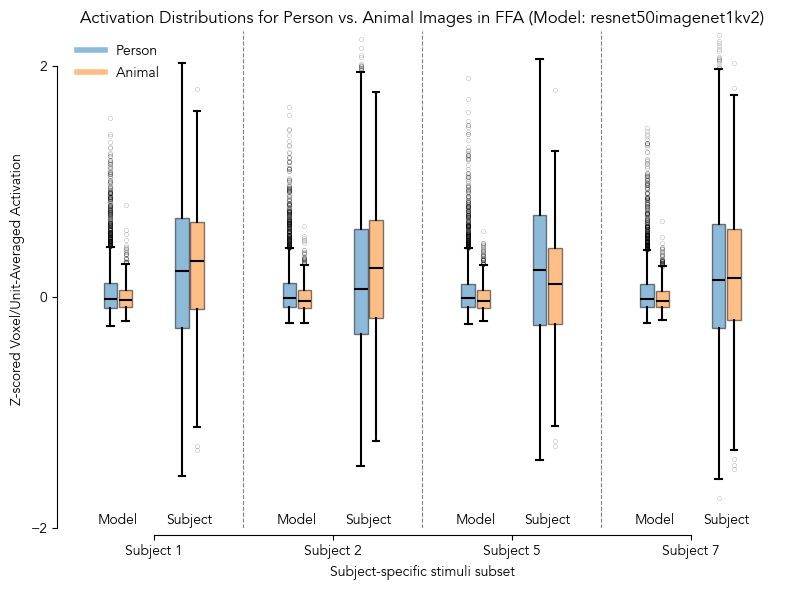

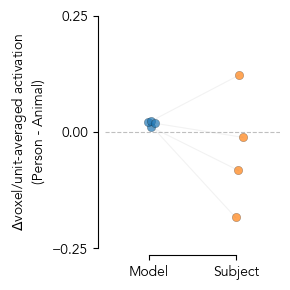

In [8]:
froi = 'FFA'
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2
person_animal_median_deltas = []
for sidx, subject in enumerate(subjects):
    ca_popmean_df_sbj = ca_popmean_df[(ca_popmean_df['froi'] == froi) & (ca_popmean_df['subject'] == subject)].copy()
    model_person_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'person']['model_activation_mean']
    model_animal_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'animal']['model_activation_mean']
    subject_person_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'person']['subject_activation_mean']
    subject_animal_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'animal']['subject_activation_mean']
    person_animal_median_deltas.append((
        model_person_points.median() - model_animal_points.median(),
        subject_person_points.median() - subject_animal_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model person, model animal, subject person, subject animal
    boxes_data = [model_person_points, model_animal_points, subject_person_points, subject_animal_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model Person', 'Model Animal', 'Subject Person', 'Subject Animal']
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        # y = bd
        # x = np.random.normal(bx, 0.02, size=len(y))
        # plt.scatter(x, y, alpha=0.6, color=bc, label=bl if sidx == 0 else "", edgecolor='k', linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f'Activation Distributions for Person vs. Animal Images in {froi} (Model: {model_name})')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label='Person'),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label='Animal')
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2, 2.3)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*person_animal_median_deltas)
x_jitter = np.random.normal(0, 0.05, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + '\n(Person - Animal)')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-0.25, 0.25)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-0.25, 0.3, 0.25))
# ax.legend(frameon=False)
plt.ylim(-0.25, 0.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

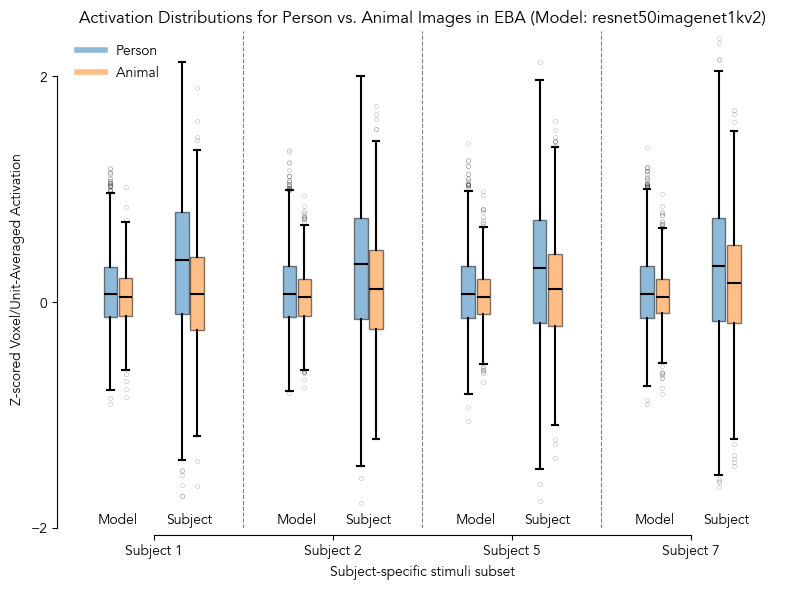

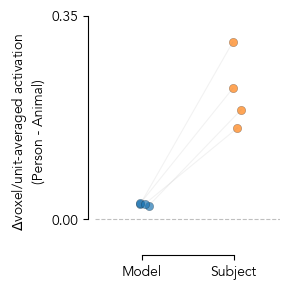

In [9]:
froi = 'EBA'
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2
person_animal_median_deltas = []
for sidx, subject in enumerate(subjects):
    ca_popmean_df_sbj = ca_popmean_df[(ca_popmean_df['froi'] == froi) & (ca_popmean_df['subject'] == subject)].copy()
    # Min-max
    # ca_popmean_df_sbj['subject_activation_mean_minmax'] = (ca_popmean_df_sbj['subject_activation_mean'] - ca_popmean_df_sbj['subject_activation_mean'].min()) / (ca_popmean_df_sbj['subject_activation_mean'].max() - ca_popmean_df_sbj['subject_activation_mean'].min())
    # ca_popmean_df_sbj['model_activation_mean_minmax'] = (ca_popmean_df_sbj['model_activation_mean'] - ca_popmean_df_sbj['model_activation_mean'].min()) / (ca_popmean_df_sbj['model_activation_mean'].max() - ca_popmean_df_sbj['model_activation_mean'].min())
    model_person_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'person']['model_activation_mean']
    model_animal_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'animal']['model_activation_mean']
    subject_person_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'person']['subject_activation_mean']
    subject_animal_points = ca_popmean_df_sbj[ca_popmean_df_sbj['person_or_animal'] == 'animal']['subject_activation_mean']
    person_animal_median_deltas.append((
        model_person_points.median() - model_animal_points.median(),
        subject_person_points.median() - subject_animal_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model person, model animal, subject person, subject animal
    boxes_data = [model_person_points, model_animal_points, subject_person_points, subject_animal_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model Person', 'Model Animal', 'Subject Person', 'Subject Animal']
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        # y = bd
        # x = np.random.normal(bx, 0.02, size=len(y))
        # plt.scatter(x, y, alpha=0.6, color=bc, label=bl if sidx == 0 else "", edgecolor='k', linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.yticks(np.arange(-2, 3, 2))
plt.title(f'Activation Distributions for Person vs. Animal Images in {froi} (Model: {model_name})')
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label='Person'),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label='Animal')
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
plt.ylim(-2, 2.4)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*person_animal_median_deltas)
x_jitter = np.random.normal(0, 0.05, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + '\n(Person - Animal)')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(0, 0.35)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks([0, 0.35])
# ax.legend(frameon=False)
plt.ylim(-0.05, 0.35)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

#### Dev: Individual samples

In [ ]:
subjects_data['FFA']

### Individual units/voxels

### Linear separability

In [11]:
kf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

def linear_svm_cv(X, y, kf=kf):
    """
    Perform K-fold cross-validation using a linear SVM.

    Parameters:
        X (array-like): Feature matrix of shape (n_samples, n_features)
        y (array-like): Labels of shape (n_samples,), binary classification
        n_splits (int): Number of folds for K-fold CV
        random_state (int, optional): Random state for reproducibility

    Returns:
        list: Accuracy for each fold
    """
    X = np.array(X)
    y = np.array(y)
    accuracies = []
    
    for train_index, test_index in kf.split(X, y):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]
        
        alpha = 0.1
        clf = LogisticRegression(penalty='l2', C=(1/alpha))
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        
        acc = accuracy_score(y_test, y_pred)
        accuracies.append(acc)
    
    return accuracies

In [12]:
froi = 'FFA'
subject = 1
# Subejct data
subject_data = np.vstack(category_activation_df[
    (category_activation_df['froi'] == froi) & 
    (category_activation_df['subject'] == subject)
]['subject_activation_all'].values)
# Model data
model_data = np.vstack(category_activation_df[
    (category_activation_df['froi'] == froi) & 
    (category_activation_df['subject'] == subject)
]['model_activation_all'].values)
# Labels
labels = category_activation_df[
    (category_activation_df['froi'] == froi) &  # type: ignore
    (category_activation_df['subject'] == subject)
]['person_or_animal'].values
labels = np.array([1 if label == 'person' else 0 for label in labels]) # person=1, animal=0
# Chance accuracy
counts = np.bincount(labels)
chance_accuracy = np.max(counts) / np.sum(counts)
print(f'Chance accuracy: {chance_accuracy:.3f}')
# Get performamces
subject_accuracies = linear_svm_cv(subject_data, labels)
model_accuracies = linear_svm_cv(model_data, labels)
print(f'Subject accuracies: {subject_accuracies}, mean: {np.mean(subject_accuracies):.3f}')
print(f'Model accuracies: {model_accuracies}, mean: {np.mean(model_accuracies):.3f}')

Chance accuracy: 0.743
Subject accuracies: [0.8581818181818182, 0.850909090909091, 0.825136612021858, 0.8160291438979964, 0.8451730418943534, 0.8670309653916212, 0.8397085610200364, 0.8378870673952641, 0.8105646630236795, 0.8360655737704918], mean: 0.839
Model accuracies: [0.8381818181818181, 0.8781818181818182, 0.8597449908925319, 0.8943533697632058, 0.8907103825136612, 0.8888888888888888, 0.8670309653916212, 0.8652094717668488, 0.8779599271402551, 0.8615664845173042], mean: 0.872


### PCA

In [14]:
seed = 42
np.random.seed(seed)
pca_file_name = f'pca_results_seed{seed}.npz'

#### Generate PCA data

In [15]:
n_components_list = [25, 50]
n_folds = 5
categories = category_activation_df["category"].unique()
frois = category_activation_df["froi"].unique()
tthreshold = category_activation_df["tthreshold"].unique()[0]
subjects = category_activation_df["subject"].unique()
model_name = category_activation_df["model_name"].unique()[0]

pca_data = {}
for n_components in n_components_list:
    print(f'Performing PCA with n_components={n_components}...')
    pca_data[str(n_components)] = {}
    for froi in frois:
        pca_data[str(n_components)][f'{froi}_{tthreshold}'] = {}
        # Loop over subjects
        for subject in subjects:
            pca_data[str(n_components)][f'{froi}_{tthreshold}'][subject] = {}
            print(f'Performing PCA for subject {subject}, froi {froi}...')
            for category in categories:
                category_results = {}
                category_data = np.vstack(category_activation_df[
                    (category_activation_df['froi'] == froi) & 
                    (category_activation_df['subject'] == subject) &
                    (category_activation_df['category'] == category)
                ]['subject_activation_all'].values)
                # Run PCA on full category data
                pca = PCA(n_components=n_components)
                pca.fit(category_data)
                category_results['full'] = {
                    "components": pca.components_,
                    "explained_variance": pca.explained_variance_,
                    "explained_variance_ratio": pca.explained_variance_ratio_,
                    "singular_values": pca.singular_values_,
                    "mean": pca.mean_,
                    "n_components": pca.n_components_,
                    "n_samples": pca.n_samples_,
                    "noise_variance": pca.noise_variance_,
                    "total_explained_variance": pca.explained_variance_.sum(),
                    "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                    "n_folds": n_folds
                }
                # Divide the data into n_folds and run PCA individually on each fold
                split_indices = np.array_split(np.arange(len(category_data)), n_folds)
                for fold_idx, indices in enumerate(split_indices):
                    # Do PCA for these indices
                    fold_data = category_data[indices]
                    pca_fold = PCA(n_components=n_components)
                    pca_fold.fit(fold_data)
                    category_results[f'fold_{fold_idx}'] = {
                        "components": pca_fold.components_,
                        "explained_variance": pca_fold.explained_variance_,
                        "explained_variance_ratio": pca_fold.explained_variance_ratio_,
                        "singular_values": pca_fold.singular_values_,
                        "mean": pca_fold.mean_,
                        "n_components": pca_fold.n_components_,
                        "n_samples": pca_fold.n_samples_,
                        "noise_variance": pca_fold.noise_variance_,
                        "total_explained_variance": pca.explained_variance_.sum(),
                        "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                        "indices": indices,
                        "n_folds": n_folds
                    }
                    # Now do PCA for the remaining indices, remove the indices from np.arange(len(category_data))
                    remaining_indices = np.setdiff1d(np.arange(len(category_data)), indices)
                    fold_data_remaining = category_data[remaining_indices]
                    pca_fold_remaining = PCA(n_components=n_components)
                    pca_fold_remaining.fit(fold_data_remaining)
                    category_results[f'fold_{fold_idx}_remaining'] = {
                        "components": pca_fold_remaining.components_,
                        "explained_variance": pca_fold_remaining.explained_variance_,
                        "explained_variance_ratio": pca_fold_remaining.explained_variance_ratio_,
                        "singular_values": pca_fold_remaining.singular_values_,
                        "mean": pca_fold_remaining.mean_,
                        "n_components": pca_fold_remaining.n_components_,
                        "n_samples": pca_fold_remaining.n_samples_,
                        "noise_variance": pca_fold_remaining.noise_variance_,
                        "total_explained_variance": pca.explained_variance_.sum(),
                        "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                        "indices": remaining_indices,
                        "n_folds": n_folds
                    }
                pca_data[str(n_components)][f'{froi}_{tthreshold}'][subject][category] = category_results
        # Run it for model data as well
        print(f'Performing PCA for {model_name}, froi {froi}...')
        pca_data[str(n_components)][f'{froi}_{tthreshold}'][model_name] = {}
        for category in categories:
            category_results = {}
            category_data = np.vstack(category_activation_df[
                (category_activation_df['froi'] == froi) & 
                (category_activation_df['model_name'] == model_name) &
                (category_activation_df['category'] == category)
            ]['model_activation_all'].values)
            # Run PCA on full category data
            pca = PCA(n_components=n_components)
            pca.fit(category_data)
            category_results['full'] = {
                "components": pca.components_,
                "explained_variance": pca.explained_variance_,
                "explained_variance_ratio": pca.explained_variance_ratio_,
                "singular_values": pca.singular_values_,
                "mean": pca.mean_,
                "n_components": pca.n_components_,
                "n_samples": pca.n_samples_,
                "noise_variance": pca.noise_variance_,
                "total_explained_variance": pca.explained_variance_.sum(),
                "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                "n_folds": n_folds
            }
            # Divide the data into n_folds and run PCA individually on each fold
            split_indices = np.array_split(np.arange(len(category_data)), n_folds)
            for fold_idx, indices in enumerate(split_indices):
                # Do PCA for these indices
                fold_data = category_data[indices]
                pca_fold = PCA(n_components=n_components)
                pca_fold.fit(fold_data)
                category_results[f'fold_{fold_idx}'] = {
                    "components": pca_fold.components_,
                    "explained_variance": pca_fold.explained_variance_,
                    "explained_variance_ratio": pca_fold.explained_variance_ratio_,
                    "singular_values": pca_fold.singular_values_,
                    "mean": pca_fold.mean_,
                    "n_components": pca_fold.n_components_,
                    "n_samples": pca_fold.n_samples_,
                    "noise_variance": pca_fold.noise_variance_,
                    "total_explained_variance": pca.explained_variance_.sum(),
                    "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                    "indices": indices,
                    "n_folds": n_folds
                }
                # Now do PCA for the remaining indices, remove the indices from np.arange(len(category_data))
                remaining_indices = np.setdiff1d(np.arange(len(category_data)), indices)
                fold_data_remaining = category_data[remaining_indices]
                pca_fold_remaining = PCA(n_components=n_components)
                pca_fold_remaining.fit(fold_data_remaining)
                category_results[f'fold_{fold_idx}_remaining'] = {
                    "components": pca_fold_remaining.components_,
                    "explained_variance": pca_fold_remaining.explained_variance_,
                    "explained_variance_ratio": pca_fold_remaining.explained_variance_ratio_,
                    "singular_values": pca_fold_remaining.singular_values_,
                    "mean": pca_fold_remaining.mean_,
                    "n_components": pca_fold_remaining.n_components_,
                    "n_samples": pca_fold_remaining.n_samples_,
                    "noise_variance": pca_fold_remaining.noise_variance_,
                    "total_explained_variance": pca.explained_variance_.sum(),
                    "total_explained_variance_ratio": pca.explained_variance_ratio_.sum(),
                    "indices": remaining_indices,
                    "n_folds": n_folds
                }
            pca_data[str(n_components)][f'{froi}_{tthreshold}'][model_name][category] = category_results
# Save pca_data with npz withour compression
np.savez(f'{RESULTS_DIR}/{pca_file_name}', **pca_data)


NameError: name 'category_activation_df' is not defined

#### Load PCA data & alignment results

In [ ]:
pca_data = np.load(f'{RESULTS_DIR}/pca_results_seed{seed}.npz', allow_pickle=True)
pca_data = {k: v.item() for k, v in pca_data.items()}
pca_alignment_results_df = pd.read_csv(f'{RESULTS_DIR}/pca_alignment_results_df.csv')

In [ ]:
subspace_angles(
    pca_data['50']['EBA_7'][1]['animal']['fold_0']['components'],
    pca_data['50']['EBA_7'][1]['animal']['fold_1']['components']
)

array([ 4.25948427,  9.95373799, 11.98590962, 15.12909339, 16.83076154,
       17.21508547, 17.98340433, 21.67472062, 21.95960835, 24.29238854,
       26.02838573, 28.53362884, 29.13582095, 29.66646482, 31.28043679,
       32.66889783, 34.7819373 , 36.5049076 , 36.68860964, 39.7706587 ,
       41.65190908, 42.65781541, 43.81443127, 44.53571588, 46.77914816,
       47.82864883, 50.18083518, 50.95108881, 52.14362736, 54.5164966 ,
       55.55380829, 57.64167344, 58.1397682 , 60.17236192, 61.30874857,
       62.67057844, 65.90007647, 67.90799427, 69.30546512, 70.40335465,
       71.74312241, 72.85289758, 73.45846282, 75.4778909 , 80.04219259,
       80.19033487, 82.86737829, 84.25095596, 88.28638681, 89.27457536])

#### Analysis

In [ ]:

n_components_list = list(pca_data.keys())
frois = list(pca_data[n_components_list[0]].keys())
systems = list(pca_data[n_components_list[0]][frois[0]].keys())
pca_alignment_results_df = [] # Get the min and the mean of the angles between each pair of categories for each subject and model
n_folds = pca_data[n_components_list[0]][frois[0]][systems[0]]['person']['full']['n_folds']
category_combinations = {
    'person': {
        'other': 'animal',
        'none': 'none',
    },
    'animal': {
        'other': 'person',
        'none': 'none',
    },
}

In [ ]:
for n_components in n_components_list:
    for froi in frois:
        for system in systems:
            for main_cat, cat_info in category_combinations.items():
                for fold_idx in range(n_folds):
                    main_cat_fold_components = pca_data[n_components][froi][system][main_cat][f'fold_{fold_idx}']['components']
                    within_cat_remaining_components = pca_data[n_components][froi][system][main_cat][f'fold_{fold_idx}_remaining']['components']
                    other_cat_full_components = pca_data[n_components][froi][system][cat_info['other']]['full']['components']
                    none_cat_full_components = pca_data[n_components][froi][system][cat_info['none']]['full']['components']
                    # Get angles
                    angle_within = subspace_angles(main_cat_fold_components, within_cat_remaining_components)
                    angle_other = subspace_angles(main_cat_fold_components, other_cat_full_components)
                    angle_none = subspace_angles(main_cat_fold_components, none_cat_full_components)
                    # Get median and min
                    angle_within_median = np.median(angle_within)
                    angle_within_min = np.min(angle_within)
                    angle_other_median = np.median(angle_other)
                    angle_other_min = np.min(angle_other)
                    angle_none_median = np.median(angle_none)
                    angle_none_min = np.min(angle_none)
                    # Get total explained variance ratio for all PCAs
                    main_cat_fold_ev_ratio = pca_data[n_components][froi][system][main_cat][f'fold_{fold_idx}']['total_explained_variance_ratio']
                    within_cat_remaining_ev_ratio = pca_data[n_components][froi][system][main_cat][f'fold_{fold_idx}_remaining']['total_explained_variance_ratio']
                    other_cat_full_ev_ratio = pca_data[n_components][froi][system][cat_info['other']]['full']['total_explained_variance_ratio']
                    none_cat_full_ev_ratio = pca_data[n_components][froi][system][cat_info['none']]['full']['total_explained_variance_ratio']
                    # Create dataframe row
                    pca_alignment_results_df.append({
                        'n_components': int(n_components),
                        'froi': froi,
                        'system': system,
                        'main_category': main_cat,
                        'fold_idx': fold_idx,
                        'other_category': cat_info['other'],
                        'none_category': cat_info['none'],
                        'within_category_angle_median': angle_within_median,
                        'within_category_angle_min': angle_within_min,
                        'other_category_angle_median': angle_other_median,
                        'other_category_angle_min': angle_other_min,
                        'none_category_angle_median': angle_none_median,
                        'none_category_angle_min': angle_none_min,
                        'within_category_angle_all': angle_within,
                        'other_category_angle_all': angle_other,
                        'none_category_angle_all': angle_none,
                        'main_cat_fold_ev_ratio': main_cat_fold_ev_ratio,
                        'within_cat_remaining_ev_ratio': within_cat_remaining_ev_ratio,
                        'other_cat_full_ev_ratio': other_cat_full_ev_ratio,
                        'none_cat_full_ev_ratio': none_cat_full_ev_ratio
                    })
pca_alignment_results_df = pd.DataFrame(pca_alignment_results_df)
print('PCA alignment results dataframe shape:', pca_alignment_results_df.shape)
# Storing pca_alignment_results_df
pca_alignment_results_df.to_csv(f'{RESULTS_DIR}/pca_alignment_results_df.csv', index=False)

PCA alignment results dataframe shape: (200, 20)


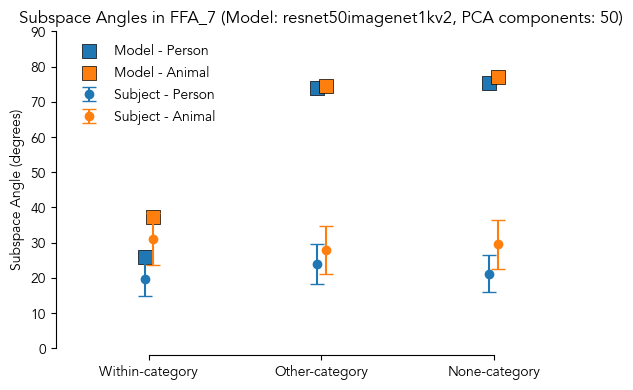

In [ ]:
# Plot
froi = 'FFA_7'
n_components = 50
metric_type = 'median' # 'median' or 'min'
categories = ['person', 'animal']
subjects = [1, 2, 5, 7]
model_name = 'resnet50imagenet1kv2'
plot_data = {
    'subjects': {
        'person': {
            'within': [],
            'other': [],
            'none': []
        },
        'animal': {
            'within': [],
            'other': [],
            'none': []
        }
    },
    'model': {
        'person': {
            'within': None,
            'other': None,
            'none': None
        },
        'animal': {
            'within': None,
            'other': None,
            'none': None
        }
    }
} # median of within-category, other-category and none-category angles for each subject and model
for subject in subjects:
    sbj_df = pca_alignment_results_df[
            (pca_alignment_results_df['froi'] == froi) &
            (pca_alignment_results_df['n_components'] == n_components) &
            (pca_alignment_results_df['system'] == subject)
        ].groupby('main_category').agg(
            {
                f'within_category_angle_{metric_type}': 'median',
                f'other_category_angle_{metric_type}': 'median',
                f'none_category_angle_{metric_type}': 'median',
            }
        )
    plot_data['subjects']['person']['within'].append(sbj_df.loc['person', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['person']['other'].append(sbj_df.loc['person', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['person']['none'].append(sbj_df.loc['person', f'none_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['within'].append(sbj_df.loc['animal', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['other'].append(sbj_df.loc['animal', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['none'].append(sbj_df.loc['animal', f'none_category_angle_{metric_type}'])
# Model
model_df = pca_alignment_results_df[
        (pca_alignment_results_df['froi'] == froi) &
        (pca_alignment_results_df['n_components'] == n_components) &
        (pca_alignment_results_df['system'] == model_name)
    ].groupby('main_category').agg(
        {
            f'within_category_angle_{metric_type}': 'median',
            f'other_category_angle_{metric_type}': 'median',
            f'none_category_angle_{metric_type}': 'median',
        }
    )
plot_data['model']['person']['within'] = model_df.loc['person', f'within_category_angle_{metric_type}']
plot_data['model']['person']['other'] = model_df.loc['person', f'other_category_angle_{metric_type}']
plot_data['model']['person']['none'] = model_df.loc['person', f'none_category_angle_{metric_type}']
plot_data['model']['animal']['within'] = model_df.loc['animal', f'within_category_angle_{metric_type}']
plot_data['model']['animal']['other'] = model_df.loc['animal', f'other_category_angle_{metric_type}']
plot_data['model']['animal']['none'] = model_df.loc['animal', f'none_category_angle_{metric_type}']


plt.figure(figsize=(6, 4))
# x-axis: within, other, none
# y-axis: angle
# separate lines for person and animal, with gray and white points
# also separate lines for subject and model, with different markers, circle and square
x_labels = ['Within-category', 'Other-category', 'None-category']
x = np.arange(len(x_labels))
# Plot subjects
for idx, category in enumerate(categories):
    y = [
        np.median(plot_data['subjects'][category]['within']),
        np.median(plot_data['subjects'][category]['other']),
        np.median(plot_data['subjects'][category]['none']),
    ]
    y_err = [
        np.std(plot_data['subjects'][category]['within']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['other']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['none']) / np.sqrt(len(subjects)),
    ]
    plt.errorbar(x + (idx-0.5)*0.05, y, yerr=y_err, fmt='o', color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Subject - {category.capitalize()}', capsize=5)
# Plot model
for idx, category in enumerate(categories):
    y = [
        plot_data['model'][category]['within'],
        plot_data['model'][category]['other'],
        plot_data['model'][category]['none'],
    ]
    plt.scatter(x + (idx-0.5)*0.05, y, marker='s', s=100, color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Model - {category.capitalize()}', edgecolor='k', linewidth=0.5)
plt.xticks(x, x_labels)
plt.ylabel('Subspace Angle (degrees)')
plt.title(f'Subspace Angles in {froi} (Model: {model_name}, PCA components: {n_components})')
plt.ylim(0, 90)
plt.xlim(-0.5, 2.5)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 2)
plt.gca().spines['left'].set_bounds(0, 90)
plt.legend(frameon=False, loc='upper left')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/pca_subspace_angles_{froi}_{n_components}components_{metric_type}.png', dpi=300)
plt.show()

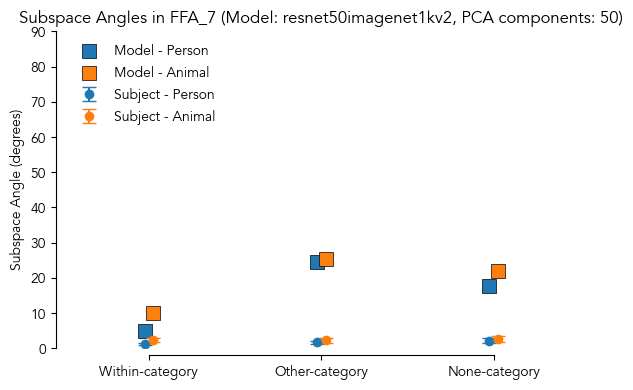

In [ ]:
# Plot
froi = 'FFA_7'
n_components = 50
metric_type = 'min' # 'median' or 'min'
categories = ['person', 'animal']
subjects = [1, 2, 5, 7]
model_name = 'resnet50imagenet1kv2'
plot_data = {
    'subjects': {
        'person': {
            'within': [],
            'other': [],
            'none': []
        },
        'animal': {
            'within': [],
            'other': [],
            'none': []
        }
    },
    'model': {
        'person': {
            'within': None,
            'other': None,
            'none': None
        },
        'animal': {
            'within': None,
            'other': None,
            'none': None
        }
    }
} # median of within-category, other-category and none-category angles for each subject and model
for subject in subjects:
    sbj_df = pca_alignment_results_df[
            (pca_alignment_results_df['froi'] == froi) &
            (pca_alignment_results_df['n_components'] == n_components) &
            (pca_alignment_results_df['system'] == subject)
        ].groupby('main_category').agg(
            {
                f'within_category_angle_{metric_type}': 'median',
                f'other_category_angle_{metric_type}': 'median',
                f'none_category_angle_{metric_type}': 'median',
            }
        )
    plot_data['subjects']['person']['within'].append(sbj_df.loc['person', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['person']['other'].append(sbj_df.loc['person', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['person']['none'].append(sbj_df.loc['person', f'none_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['within'].append(sbj_df.loc['animal', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['other'].append(sbj_df.loc['animal', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['none'].append(sbj_df.loc['animal', f'none_category_angle_{metric_type}'])
# Model
model_df = pca_alignment_results_df[
        (pca_alignment_results_df['froi'] == froi) &
        (pca_alignment_results_df['n_components'] == n_components) &
        (pca_alignment_results_df['system'] == model_name)
    ].groupby('main_category').agg(
        {
            f'within_category_angle_{metric_type}': 'median',
            f'other_category_angle_{metric_type}': 'median',
            f'none_category_angle_{metric_type}': 'median',
        }
    )
plot_data['model']['person']['within'] = model_df.loc['person', f'within_category_angle_{metric_type}']
plot_data['model']['person']['other'] = model_df.loc['person', f'other_category_angle_{metric_type}']
plot_data['model']['person']['none'] = model_df.loc['person', f'none_category_angle_{metric_type}']
plot_data['model']['animal']['within'] = model_df.loc['animal', f'within_category_angle_{metric_type}']
plot_data['model']['animal']['other'] = model_df.loc['animal', f'other_category_angle_{metric_type}']
plot_data['model']['animal']['none'] = model_df.loc['animal', f'none_category_angle_{metric_type}']


plt.figure(figsize=(6, 4))
# x-axis: within, other, none
# y-axis: angle
# separate lines for person and animal, with gray and white points
# also separate lines for subject and model, with different markers, circle and square
x_labels = ['Within-category', 'Other-category', 'None-category']
x = np.arange(len(x_labels))
# Plot subjects
for idx, category in enumerate(categories):
    y = [
        np.median(plot_data['subjects'][category]['within']),
        np.median(plot_data['subjects'][category]['other']),
        np.median(plot_data['subjects'][category]['none']),
    ]
    y_err = [
        np.std(plot_data['subjects'][category]['within']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['other']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['none']) / np.sqrt(len(subjects)),
    ]
    plt.errorbar(x + (idx-0.5)*0.05, y, yerr=y_err, fmt='o', color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Subject - {category.capitalize()}', capsize=5)
# Plot model
for idx, category in enumerate(categories):
    y = [
        plot_data['model'][category]['within'],
        plot_data['model'][category]['other'],
        plot_data['model'][category]['none'],
    ]
    plt.scatter(x + (idx-0.5)*0.05, y, marker='s', s=100, color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Model - {category.capitalize()}', edgecolor='k', linewidth=0.5)
plt.xticks(x, x_labels)
plt.ylabel('Subspace Angle (degrees)')
plt.title(f'Subspace Angles in {froi} (Model: {model_name}, PCA components: {n_components})')
plt.ylim(0, 90)
plt.xlim(-0.5, 2.5)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 2)
plt.gca().spines['left'].set_bounds(0, 90)
plt.legend(frameon=False, loc='upper left')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/pca_subspace_angles_{froi}_{n_components}components_{metric_type}.png', dpi=300)
plt.show()

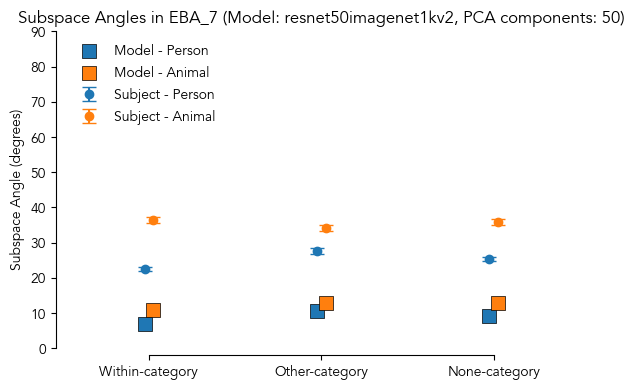

In [ ]:
# Plot
froi = 'EBA_7'
n_components = 50
metric_type = 'median' # 'median' or 'min'
categories = ['person', 'animal']
subjects = [1, 2, 5, 7]
model_name = 'resnet50imagenet1kv2'
plot_data = {
    'subjects': {
        'person': {
            'within': [],
            'other': [],
            'none': []
        },
        'animal': {
            'within': [],
            'other': [],
            'none': []
        }
    },
    'model': {
        'person': {
            'within': None,
            'other': None,
            'none': None
        },
        'animal': {
            'within': None,
            'other': None,
            'none': None
        }
    }
} # median of within-category, other-category and none-category angles for each subject and model
for subject in subjects:
    sbj_df = pca_alignment_results_df[
            (pca_alignment_results_df['froi'] == froi) &
            (pca_alignment_results_df['n_components'] == n_components) &
            (pca_alignment_results_df['system'] == subject)
        ].groupby('main_category').agg(
            {
                f'within_category_angle_{metric_type}': 'median',
                f'other_category_angle_{metric_type}': 'median',
                f'none_category_angle_{metric_type}': 'median',
            }
        )
    plot_data['subjects']['person']['within'].append(sbj_df.loc['person', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['person']['other'].append(sbj_df.loc['person', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['person']['none'].append(sbj_df.loc['person', f'none_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['within'].append(sbj_df.loc['animal', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['other'].append(sbj_df.loc['animal', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['none'].append(sbj_df.loc['animal', f'none_category_angle_{metric_type}'])
# Model
model_df = pca_alignment_results_df[
        (pca_alignment_results_df['froi'] == froi) &
        (pca_alignment_results_df['n_components'] == n_components) &
        (pca_alignment_results_df['system'] == model_name)
    ].groupby('main_category').agg(
        {
            f'within_category_angle_{metric_type}': 'median',
            f'other_category_angle_{metric_type}': 'median',
            f'none_category_angle_{metric_type}': 'median',
        }
    )
plot_data['model']['person']['within'] = model_df.loc['person', f'within_category_angle_{metric_type}']
plot_data['model']['person']['other'] = model_df.loc['person', f'other_category_angle_{metric_type}']
plot_data['model']['person']['none'] = model_df.loc['person', f'none_category_angle_{metric_type}']
plot_data['model']['animal']['within'] = model_df.loc['animal', f'within_category_angle_{metric_type}']
plot_data['model']['animal']['other'] = model_df.loc['animal', f'other_category_angle_{metric_type}']
plot_data['model']['animal']['none'] = model_df.loc['animal', f'none_category_angle_{metric_type}']


plt.figure(figsize=(6, 4))
# x-axis: within, other, none
# y-axis: angle
# separate lines for person and animal, with gray and white points
# also separate lines for subject and model, with different markers, circle and square
x_labels = ['Within-category', 'Other-category', 'None-category']
x = np.arange(len(x_labels))
# Plot subjects
for idx, category in enumerate(categories):
    y = [
        np.median(plot_data['subjects'][category]['within']),
        np.median(plot_data['subjects'][category]['other']),
        np.median(plot_data['subjects'][category]['none']),
    ]
    y_err = [
        np.std(plot_data['subjects'][category]['within']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['other']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['none']) / np.sqrt(len(subjects)),
    ]
    plt.errorbar(x + (idx-0.5)*0.05, y, yerr=y_err, fmt='o', color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Subject - {category.capitalize()}', capsize=5)
# Plot model
for idx, category in enumerate(categories):
    y = [
        plot_data['model'][category]['within'],
        plot_data['model'][category]['other'],
        plot_data['model'][category]['none'],
    ]
    plt.scatter(x + (idx-0.5)*0.05, y, marker='s', s=100, color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Model - {category.capitalize()}', edgecolor='k', linewidth=0.5)
plt.xticks(x, x_labels)
plt.ylabel('Subspace Angle (degrees)')
plt.title(f'Subspace Angles in {froi} (Model: {model_name}, PCA components: {n_components})')
plt.ylim(0, 90)
plt.xlim(-0.5, 2.5)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 2)
plt.gca().spines['left'].set_bounds(0, 90)
plt.legend(frameon=False, loc='upper left')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/pca_subspace_angles_{froi}_{n_components}components_{metric_type}.png', dpi=300)
plt.show()

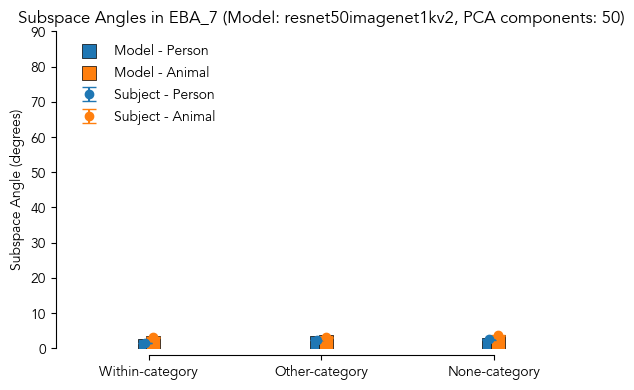

In [ ]:
# Plot
froi = 'EBA_7'
n_components = 50
metric_type = 'min' # 'median' or 'min'
categories = ['person', 'animal']
subjects = [1, 2, 5, 7]
model_name = 'resnet50imagenet1kv2'
plot_data = {
    'subjects': {
        'person': {
            'within': [],
            'other': [],
            'none': []
        },
        'animal': {
            'within': [],
            'other': [],
            'none': []
        }
    },
    'model': {
        'person': {
            'within': None,
            'other': None,
            'none': None
        },
        'animal': {
            'within': None,
            'other': None,
            'none': None
        }
    }
} # median of within-category, other-category and none-category angles for each subject and model
for subject in subjects:
    sbj_df = pca_alignment_results_df[
            (pca_alignment_results_df['froi'] == froi) &
            (pca_alignment_results_df['n_components'] == n_components) &
            (pca_alignment_results_df['system'] == subject)
        ].groupby('main_category').agg(
            {
                f'within_category_angle_{metric_type}': 'median',
                f'other_category_angle_{metric_type}': 'median',
                f'none_category_angle_{metric_type}': 'median',
            }
        )
    plot_data['subjects']['person']['within'].append(sbj_df.loc['person', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['person']['other'].append(sbj_df.loc['person', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['person']['none'].append(sbj_df.loc['person', f'none_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['within'].append(sbj_df.loc['animal', f'within_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['other'].append(sbj_df.loc['animal', f'other_category_angle_{metric_type}'])
    plot_data['subjects']['animal']['none'].append(sbj_df.loc['animal', f'none_category_angle_{metric_type}'])
# Model
model_df = pca_alignment_results_df[
        (pca_alignment_results_df['froi'] == froi) &
        (pca_alignment_results_df['n_components'] == n_components) &
        (pca_alignment_results_df['system'] == model_name)
    ].groupby('main_category').agg(
        {
            f'within_category_angle_{metric_type}': 'median',
            f'other_category_angle_{metric_type}': 'median',
            f'none_category_angle_{metric_type}': 'median',
        }
    )
plot_data['model']['person']['within'] = model_df.loc['person', f'within_category_angle_{metric_type}']
plot_data['model']['person']['other'] = model_df.loc['person', f'other_category_angle_{metric_type}']
plot_data['model']['person']['none'] = model_df.loc['person', f'none_category_angle_{metric_type}']
plot_data['model']['animal']['within'] = model_df.loc['animal', f'within_category_angle_{metric_type}']
plot_data['model']['animal']['other'] = model_df.loc['animal', f'other_category_angle_{metric_type}']
plot_data['model']['animal']['none'] = model_df.loc['animal', f'none_category_angle_{metric_type}']


plt.figure(figsize=(6, 4))
# x-axis: within, other, none
# y-axis: angle
# separate lines for person and animal, with gray and white points
# also separate lines for subject and model, with different markers, circle and square
x_labels = ['Within-category', 'Other-category', 'None-category']
x = np.arange(len(x_labels))
# Plot subjects
for idx, category in enumerate(categories):
    y = [
        np.median(plot_data['subjects'][category]['within']),
        np.median(plot_data['subjects'][category]['other']),
        np.median(plot_data['subjects'][category]['none']),
    ]
    y_err = [
        np.std(plot_data['subjects'][category]['within']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['other']) / np.sqrt(len(subjects)),
        np.std(plot_data['subjects'][category]['none']) / np.sqrt(len(subjects)),
    ]
    plt.errorbar(x + (idx-0.5)*0.05, y, yerr=y_err, fmt='o', color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Subject - {category.capitalize()}', capsize=5)
# Plot model
for idx, category in enumerate(categories):
    y = [
        plot_data['model'][category]['within'],
        plot_data['model'][category]['other'],
        plot_data['model'][category]['none'],
    ]
    plt.scatter(x + (idx-0.5)*0.05, y, marker='s', s=100, color='#1f77b4' if category == 'person' else '#ff7f0e', label=f'Model - {category.capitalize()}', edgecolor='k', linewidth=0.5)
plt.xticks(x, x_labels)
plt.ylabel('Subspace Angle (degrees)')
plt.title(f'Subspace Angles in {froi} (Model: {model_name}, PCA components: {n_components})')
plt.ylim(0, 90)
plt.xlim(-0.5, 2.5)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 2)
plt.gca().spines['left'].set_bounds(0, 90)
plt.legend(frameon=False, loc='upper left')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/pca_subspace_angles_{froi}_{n_components}components_{metric_type}.png', dpi=300)
plt.show()

### Controlled person vs. animals

In [ ]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_name = 'resnet50imagenet1kv2'
froi = 'FFA'
tthreshold = 7
model = ma.get_model(model_name)
model.eval()
model.to(DEVICE)
layer = ma.get_froi_models_layers(froi, froi)[model_name]

batch_size = 512

afhq_acts = model_utils.get_dataset_activations(
    MODELS_DIR, paths.AFHQV2_VAL_DIR, model, layer, dataset='afhqv2', froi=froi, tthreshold=tthreshold,
    froi_localizer='grillspector', froi_localizer_dir=paths.GRILLSPECTOR_LOCALIZER_DIR, 
    batch_size=batch_size, device=DEVICE
)

celebahq_acts = model_utils.get_dataset_activations(
    MODELS_DIR, paths.CELEBAHQ_VAL_DIR, model, layer, dataset='celebahq', froi=froi, tthreshold=tthreshold,
    froi_localizer='grillspector', froi_localizer_dir=paths.GRILLSPECTOR_LOCALIZER_DIR, 
    batch_size=batch_size, device=DEVICE
)

afhq_acts_z = (afhq_acts - afhq_acts.mean(0)) / afhq_acts.std(0)
celebahq_acts_z = (celebahq_acts - celebahq_acts.mean(0)) / celebahq_acts.std(0)

100%|██████████| 4/4 [00:31<00:00,  7.98s/it]


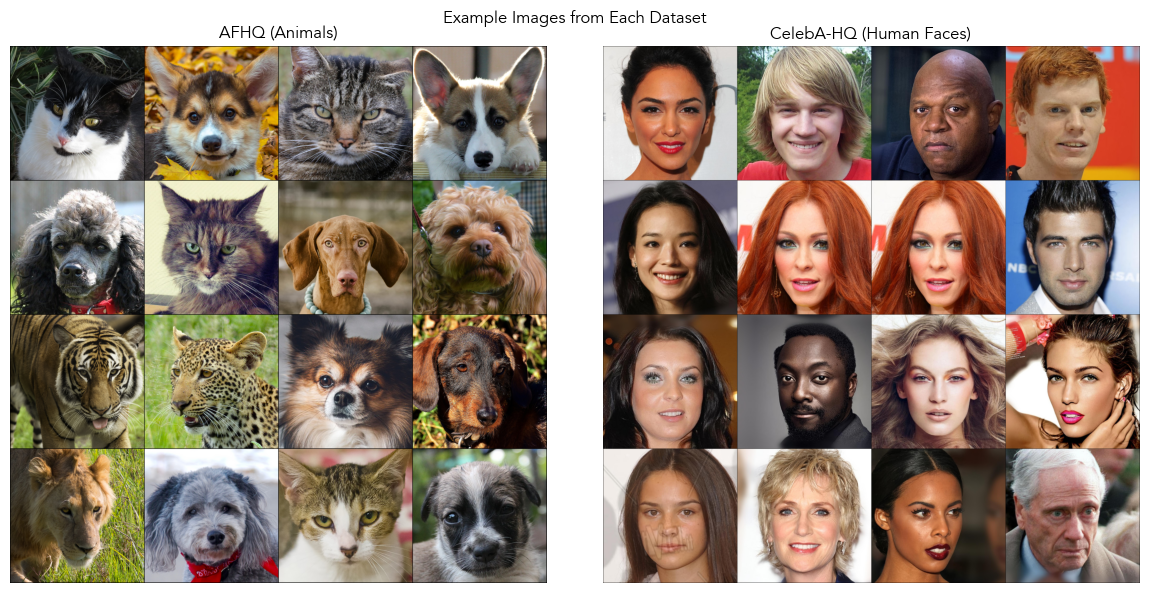

In [19]:
# Make a torchvision grid of some example images from each dataset
import torchvision.utils as vutils
afhqv2_ds = afhqv2.get_val_dataset(paths.AFHQV2_VAL_DIR, None)
celebahq_ds = celebahq.get_val_dataset(paths.CELEBAHQ_VAL_DIR, None)
n_imgs_show = 16

# Convert PIL images to tensors
afhq_imgs = []
celebahq_imgs = []

for i in range(16):
    # Get PIL image and convert to tensor
    # Get random indices for AFHQ and CelebA-HQ datasets
    afhq_idx = np.random.randint(0, len(afhqv2_ds))
    celebahq_idx = np.random.randint(0, len(celebahq_ds))
    
    # Get the images at those random indices
    afhq_img = afhqv2_ds[afhq_idx][0]
    celebahq_img = celebahq_ds[celebahq_idx][0]
    
    # Convert PIL images to tensors (0-1 range)
    afhq_tensor = torch.tensor(np.array(afhq_img)).permute(2, 0, 1).float() / 255.0
    celebahq_tensor = torch.tensor(np.array(celebahq_img)).permute(2, 0, 1).float() / 255.0
    
    afhq_imgs.append(afhq_tensor)
    celebahq_imgs.append(celebahq_tensor)

# Stack tensors into batches
afhq_imgs = torch.stack(afhq_imgs)
celebahq_imgs = torch.stack(celebahq_imgs)

# Create image grids
afhq_grid = vutils.make_grid(afhq_imgs, nrow=4, padding=2, normalize=True)
celebahq_grid = vutils.make_grid(celebahq_imgs, nrow=4, padding=2, normalize=True)

# Display grids
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(afhq_grid.permute(1, 2, 0).cpu().numpy())
plt.axis('off')
plt.title('AFHQ (Animals)')

plt.subplot(1, 2, 2)
plt.imshow(celebahq_grid.permute(1, 2, 0).cpu().numpy())
plt.axis('off')
plt.title('CelebA-HQ (Human Faces)')

plt.suptitle('Example Images from Each Dataset')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/example_images_afhq_celebahq.png', dpi=300)
plt.show()


#### Population mean

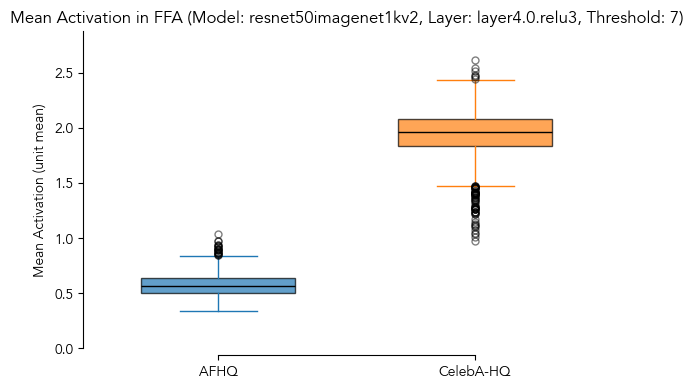

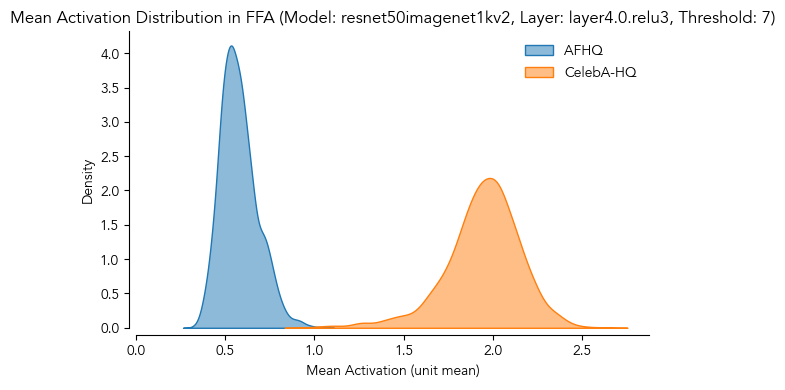

In [ ]:
afhq_acts_unitmean = afhq_acts.mean(-1).cpu().numpy()
celebahq_acts_unitmean = celebahq_acts.mean(-1).cpu().numpy()

colors = {
    'afhq': '#1f77b4',
    'celebahq': '#ff7f0e',
}

# Plot as boxplots
plt.figure(figsize=(6, 4))
data = [afhq_acts_unitmean, celebahq_acts_unitmean]
boxes = plt.boxplot(data, positions=[0, 1], widths=0.6, patch_artist=True,
            boxprops=dict(alpha=0.7),
            medianprops=dict(color='black'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),
            flierprops=dict(marker='o', alpha=0.5, markersize=5))

# Set different colors for each box
boxes['boxes'][0].set(facecolor=colors['afhq'])  # AFHQ color
boxes['boxes'][1].set(facecolor=colors['celebahq'])  # CelebA-HQ color
for i, color in enumerate([colors['afhq'], colors['celebahq']]):
    boxes['fliers'][i].set(color=color)
    boxes['whiskers'][i*2].set(color=color)
    boxes['whiskers'][i*2+1].set(color=color)
    boxes['caps'][i*2].set(color=color)
    boxes['caps'][i*2+1].set(color=color)
    
plt.xticks([0, 1], ['AFHQ', 'CelebA-HQ'])
plt.ylabel('Mean Activation (unit mean)')
plt.title(f'Mean Activation in {froi} (Model: {model_name}, Layer: {layer}, Threshold: {tthreshold})')
plt.ylim(0, np.max([afhq_acts_unitmean.max(), celebahq_acts_unitmean.max()]) * 1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, 1)
plt.gca().spines['left'].set_bounds(0, np.max([afhq_acts_unitmean.max(), celebahq_acts_unitmean.max()]) * 1.1)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/mean_activation_{froi}_{model_name}_{layer}_t{tthreshold}.png', dpi=300)
plt.show()

# Also plot as distributions
plt.figure(figsize=(6, 4))
sns.kdeplot(afhq_acts_unitmean, fill=True, color='#1f77b4', alpha=0.5, label='AFHQ')
sns.kdeplot(celebahq_acts_unitmean, fill=True, color='#ff7f0e', alpha=0.5, label='CelebA-HQ')
plt.xlabel('Mean Activation (unit mean)')
plt.ylabel('Density')
plt.title(f'Mean Activation Distribution in {froi} (Model: {model_name}, Layer: {layer}, Threshold: {tthreshold})')
plt.xlim(0, np.max([afhq_acts_unitmean.max(), celebahq_acts_unitmean.max()]) * 1.1)
plt.ylim(0)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, np.max([afhq_acts_unitmean.max(), celebahq_acts_unitmean.max()]) * 1.1)
plt.gca().spines['left'].set_bounds(0, plt.ylim()[1])
plt.legend(frameon=False)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/mean_activation_distribution_{froi}_{model_name}_{layer}_t{tthreshold}.png', dpi=300)
plt.show()

#### Individual units

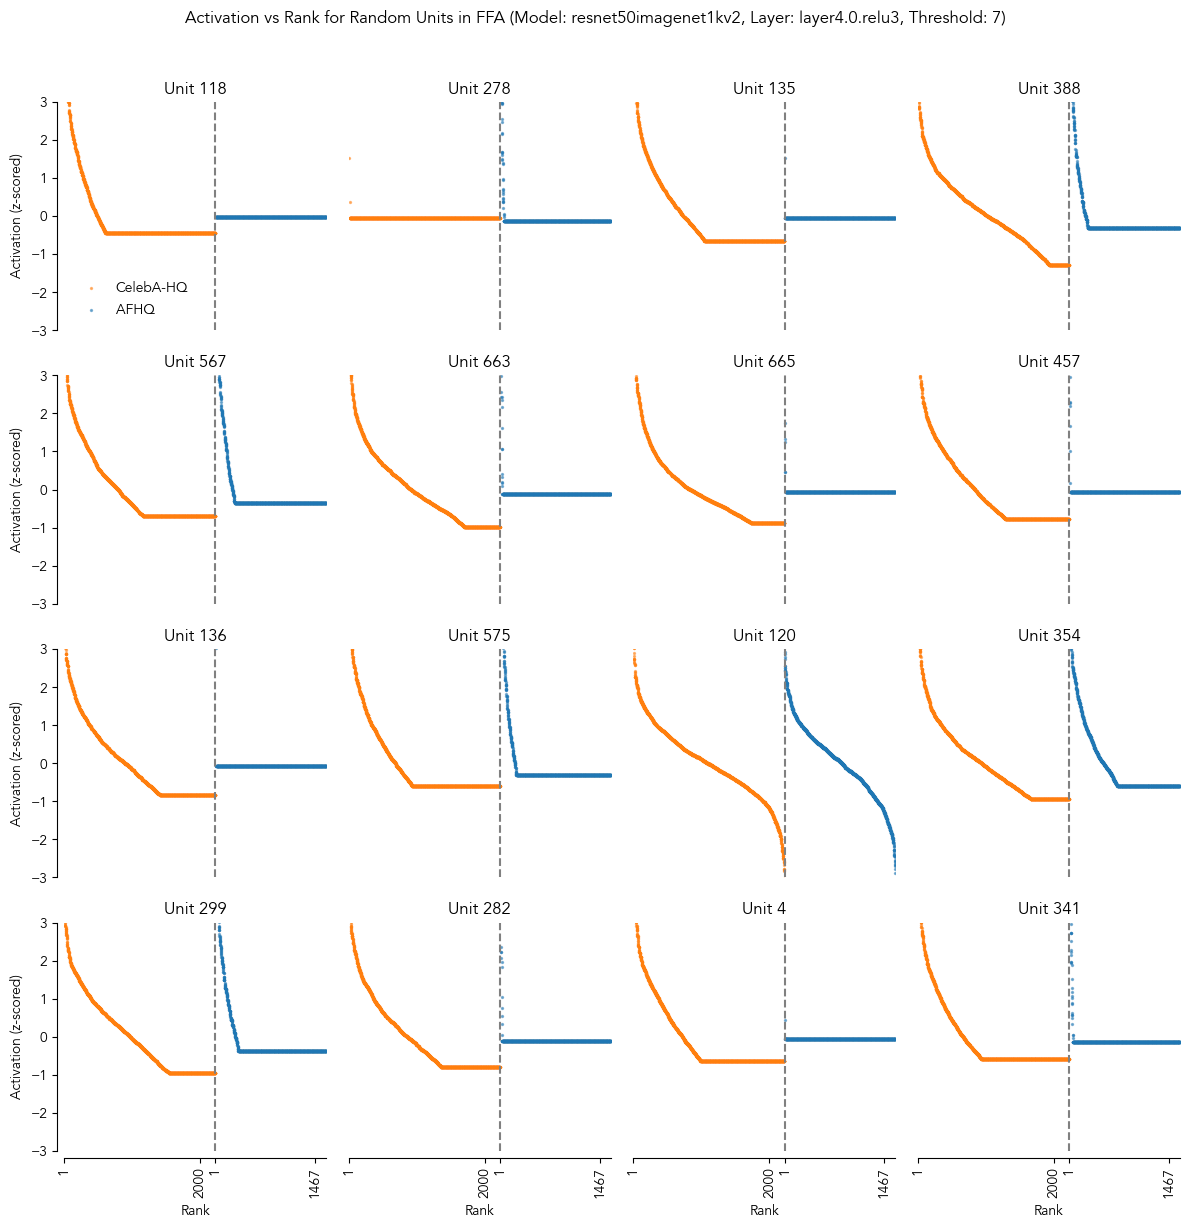

In [35]:
# afhq_acts_z, celebahq_acts_z
# Make a 4x4 plot of 16 random units, showing the activation vs rank across both datasets, make a vertical separating line between the two datasets and rank individually
n_units_show = 16
random_units = np.random.choice(afhq_acts_z.shape[1], n_units_show, replace=False)
plt.figure(figsize=(12, 12))
for i, unit in enumerate(random_units):
    plt.subplot(4, 4, i+1)
    # Get activations for this unit
    afhq_unit_acts = afhq_acts_z[:, unit].cpu().numpy()
    celebahq_unit_acts = celebahq_acts_z[:, unit].cpu().numpy()
    # Get ranks
    celebahq_ranks = np.argsort(np.argsort(-celebahq_unit_acts)) + 1  # Rank 1 is highest activation
    afhq_ranks = np.argsort(np.argsort(-afhq_unit_acts)) + 1  # Rank 1 is highest activation
    # Plot CelebA-HQ first
    plt.scatter(celebahq_ranks, celebahq_unit_acts, s=2, color='#ff7f0e', alpha=0.5, label='CelebA-HQ' if i == 0 else "")
    # Plot AFHQ after, with offset
    plt.scatter(afhq_ranks + len(celebahq_unit_acts), afhq_unit_acts, s=2, color='#1f77b4', alpha=0.5, label='AFHQ' if i == 0 else "")
    # Add vertical separation line
    plt.axvline(x=len(celebahq_unit_acts) + 0.5, color='gray', linestyle='--')
    # Add x-ticks for start and end of each dataset
    if i >= 12:  # Only for bottom row to avoid clutter
        plt.xticks([1, len(celebahq_unit_acts)*0.9, len(celebahq_unit_acts) + 1, len(celebahq_unit_acts) + len(afhq_unit_acts)*0.9], 
                  ['1', str(len(celebahq_unit_acts)), '1', str(len(afhq_unit_acts))])
    else:
        plt.xticks([])
        plt.gca().spines['bottom'].set_visible(False)
    if i%4 !=0:
        plt.gca().spines['left'].set_visible(False)
        plt.gca().yaxis.set_visible(False)
    plt.tick_params(axis='x', labelrotation=90) # Rotate by 45 degrees
    plt.title(f'Unit {unit}')
    if i % 4 == 0:  # Only for leftmost plots
        plt.ylabel('Activation (z-scored)')
    if i >= 12:  # Only for bottom row
        plt.xlabel('Rank')
    plt.ylim(-3, 3)
    plt.xlim(0, len(afhq_unit_acts) + len(celebahq_unit_acts) + 1)
    if i == 0:
        plt.legend(frameon=False)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_bounds(0, len(afhq_unit_acts) + len(celebahq_unit_acts) + 1)
    plt.gca().spines['left'].set_bounds(-3, 3)
plt.suptitle(f'Activation vs Rank for Random Units in {froi} (Model: {model_name}, Layer: {layer}, Threshold: {tthreshold})', y=1.02)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_vs_rank_random_units_{froi}_{model_name}_{layer}_t{tthreshold}.png', dpi=300)
plt.show()

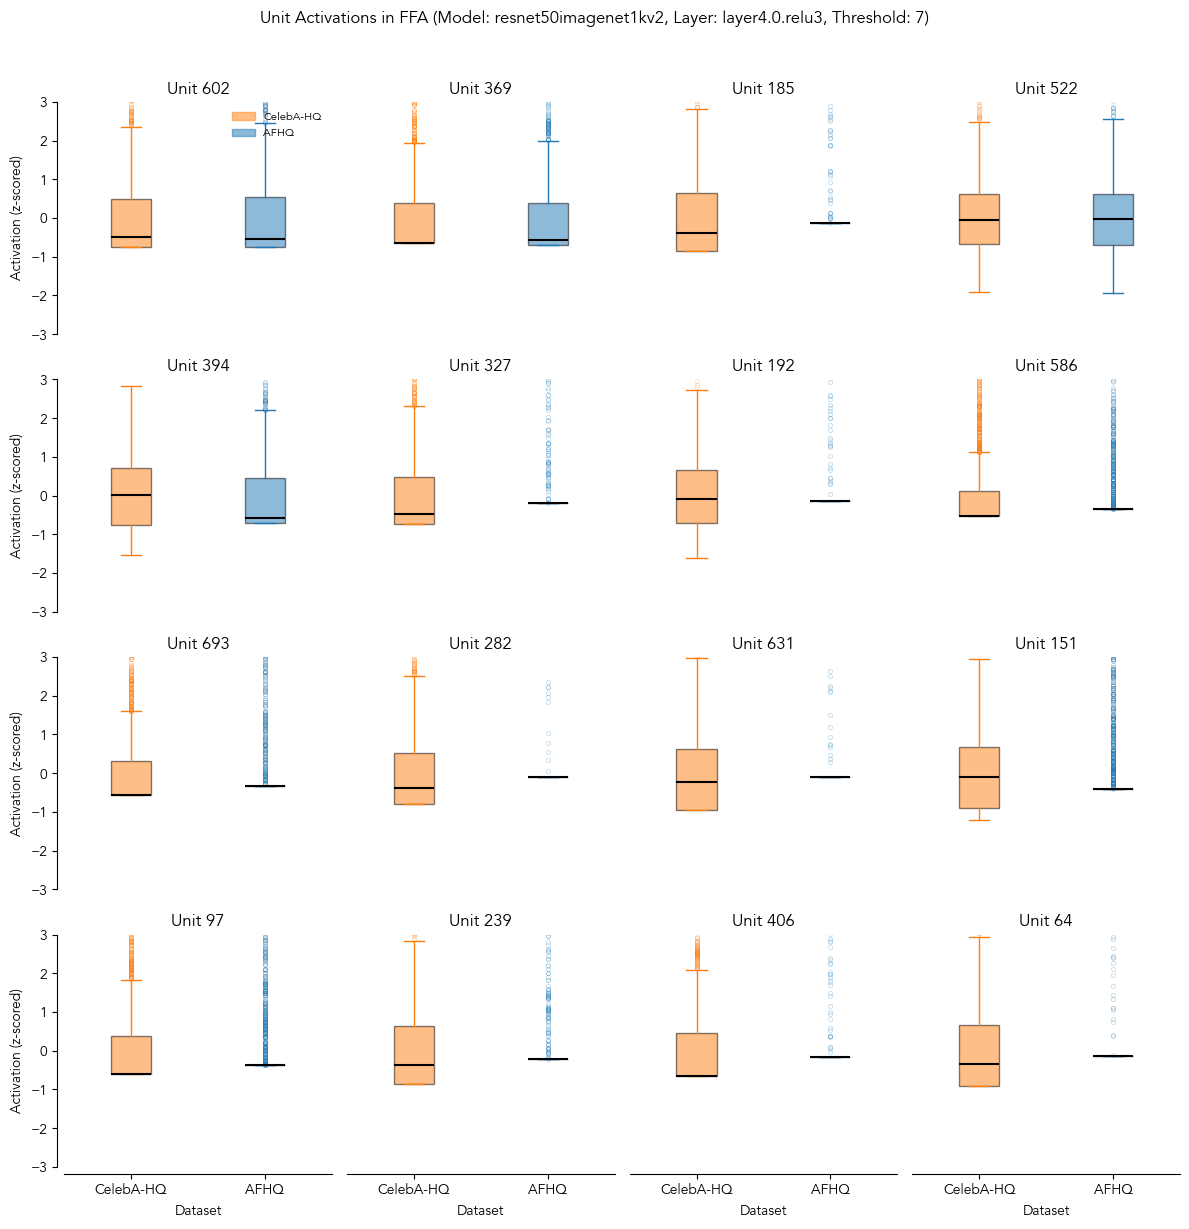

In [37]:
# afhq_acts_z, celebahq_acts_z
# Make a 4x4 plot of 16 random units, showing the activation vs rank across both datasets, make a vertical separating line between the two datasets and rank individually
n_units_show = 16
random_units = np.random.choice(afhq_acts_z.shape[1], n_units_show, replace=False)
plt.figure(figsize=(12, 12))

for i, unit in enumerate(random_units):
    plt.subplot(4, 4, i+1)
    
    # Get activations for this unit
    afhq_unit_acts = afhq_acts_z[:, unit].cpu().numpy()
    celebahq_unit_acts = celebahq_acts_z[:, unit].cpu().numpy()
    
    # Create boxplot
    box_data = [celebahq_unit_acts, afhq_unit_acts]
    box_colors = ['#ff7f0e', '#1f77b4']  # CelebA-HQ, AFHQ
    box_labels = ['CelebA-HQ', 'AFHQ']
    
    boxplot = plt.boxplot(box_data, positions=[0, 1], widths=0.3, patch_artist=True,
                boxprops=dict(alpha=0.5),
                medianprops=dict(color='black', linewidth=1.5),
                whiskerprops=dict(color='black', linewidth=1),
                capprops=dict(color='black', linewidth=1),
                flierprops=dict(marker='o', markersize=3, alpha=0.3, markeredgewidth=0.5))
    
    # Color the boxes
    for patch, color in zip(boxplot['boxes'], box_colors):
        patch.set(facecolor=color)
        
    # Set the whiskers and fliers to match the box colors
    for j, color in enumerate(box_colors):
        boxplot['fliers'][j].set(color=color, markeredgecolor=color)
        boxplot['whiskers'][j*2].set(color=color)
        boxplot['whiskers'][j*2+1].set(color=color)
        boxplot['caps'][j*2].set(color=color)
        boxplot['caps'][j*2+1].set(color=color)
    
    # Add axis labels and formatting
    plt.xticks([0, 1], box_labels if i >= 12 else [])
    plt.title(f'Unit {unit}')
    
    if i % 4 == 0:  # Only for leftmost plots
        plt.ylabel('Activation (z-scored)')
        
    if i >= 12:  # Only for bottom row
        plt.xlabel('Dataset')
    else:
        plt.gca().spines['bottom'].set_visible(False)
        # Remove x-ticks
        plt.xticks([])
        
    if i % 4 != 0:
        plt.gca().spines['left'].set_visible(False)
        plt.gca().yaxis.set_visible(False)
        
    # Add a legend to the first plot only
    if i == 0:
        handles = [plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in box_colors]
        plt.legend(handles, box_labels, frameon=False, loc='upper right', fontsize=8)
    
    # Set limits and formatting
    plt.ylim(-3, 3)
    plt.xlim(-0.5, 1.5)
    plt.gca().spines['top'].set_visible(False)
    plt.gca().spines['right'].set_visible(False)
    plt.gca().spines['left'].set_position(('outward', 5))
    plt.gca().spines['bottom'].set_position(('outward', 5))

plt.suptitle(f'Unit Activations in {froi} (Model: {model_name}, Layer: {layer}, Threshold: {tthreshold})', y=1.02)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_boxplots_random_units_{froi}_{model_name}_{layer}_t{tthreshold}.png', dpi=300)
plt.show()

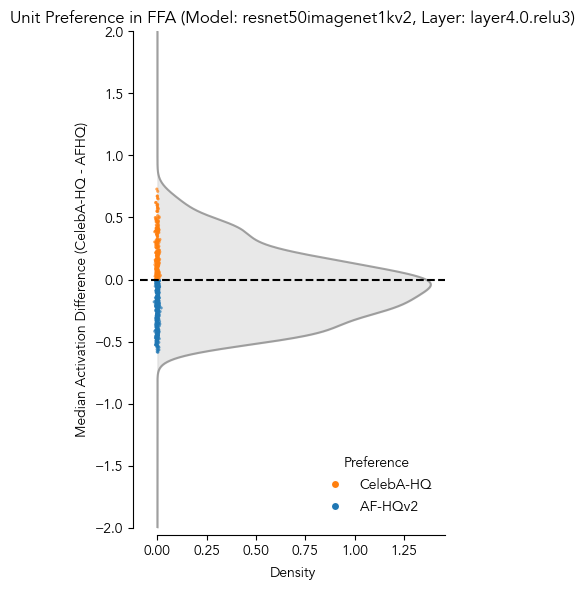

In [45]:
from matplotlib.lines import Line2D
from scipy import stats

# Loop over each unit, get the median activation in each dataset, then take the difference between celebahq and afhq
# Then make a swarmplot with kde overlay of the differences on y-axis
unit_diffs = []
for unit in range(afhq_acts_z.shape[1]):
    afhq_unit_acts = afhq_acts_z[:, unit].cpu().numpy()
    celebahq_unit_acts = celebahq_acts_z[:, unit].cpu().numpy()
    median_afhq = np.median(afhq_unit_acts)
    median_celebahq = np.median(celebahq_unit_acts)
    diff = median_celebahq - median_afhq
    unit_diffs.append(diff)
unit_diffs = np.array(unit_diffs)
diffs_df = pd.DataFrame({
    'unit': np.arange(len(unit_diffs)),
    'median_diff': unit_diffs
})
diffs_df['preference'] = diffs_df['median_diff'].apply(lambda x: 'CelebA-HQ' if x > 0 else ('AFHQ' if x < 0 else 'Neutral'))
diffs_df = diffs_df.sort_values('median_diff')
plt.figure(figsize=(4, 6))
# Calculate KDE values
kde = stats.gaussian_kde(diffs_df['median_diff'])
x_kde = np.linspace(-2, 2, 1000)
y_kde = kde(x_kde)

# Plot KDE horizontally
plt.fill_betweenx(x_kde, y_kde, alpha=0.5, color='lightgray')
plt.plot(y_kde, x_kde, color='gray', alpha=0.7)

# Get colors based on preference
colors = diffs_df['preference'].map({'CelebA-HQ': '#ff7f0e', 'AFHQ': '#1f77b4', 'Neutral': 'gray'})

# Create jitter
np.random.seed(42)  # For reproducibility
x_jitter = np.random.normal(0, 0.005, size=len(diffs_df))

# Plot jittered points
plt.scatter(x_jitter, diffs_df['median_diff'], c=colors, s=5, alpha=0.7, edgecolor='none')

# Add reference line at 0
plt.axhline(0, color='black', linestyle='--')

plt.ylabel('Median Activation Difference (CelebA-HQ - AFHQ)')
plt.xlabel('Density')
plt.title(f'Unit Preference in {froi} (Model: {model_name}, Layer: {layer})')
plt.ylim(-2, 2)

# Add legend
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#ff7f0e', markersize=6, label='CelebA-HQ Preference'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#1f77b4', markersize=6, label='AFHQ Preference')
]
plt.legend(legend_elements, ['CelebA-HQ', 'AF-HQv2'], frameon=False, title='Preference', loc='lower right')

plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['left'].set_bounds(-2, 2)
plt.gca().spines['bottom'].set_bounds(0, plt.xlim()[1])

plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/unit_preference_{froi}_{model_name}_{layer}_t{tthreshold}.png', dpi=300)
plt.show()

### RDM

In [45]:
froi = 'FFA'
subject = 1
ca_sbj_froi_df = category_activation_df[(category_activation_df['froi'] == froi) & (category_activation_df['subject'] == subject)].copy()
subject_activations = []
model_activations = []
categories = []
for idx, row in ca_sbj_froi_df.iterrows():
    subject_activations.append(row['subject_activation_all'])
    model_activations.append(row['model_activation_all'])
    categories.append(row['person_or_animal'])
subject_activations = np.array(subject_activations) # n_images x n_voxels
model_activations = np.array(model_activations) # n_images x n_units
categories = np.array(categories) # n_images

# Z-score within subject
# subject_activations = (subject_activations - subject_activations.mean(axis=0)) / subject_activations.std(axis=0)
# model_activations = (model_activations - model_activations.mean(axis=0)) / model_activations.std(axis=0)

In [46]:
subject_activations.shape, model_activations.shape, categories.shape

((5492, 156), (5492, 729), (5492,))

In [47]:
# Create an RDM using correlation distance for subject_activations and model_activations
subject_rdm_ = scipy.spatial.distance.pdist(subject_activations, metric='euclidean')
model_rdm_ = scipy.spatial.distance.pdist(model_activations, metric='euclidean')
# Convert to squareform
subject_rdm = scipy.spatial.distance.squareform(subject_rdm_)
model_rdm = scipy.spatial.distance.squareform(model_rdm_)

# Ensure the values are in [0, 1] range by clipping if needed
# subject_rdm = np.clip(subject_rdm, 0, 2)
# model_rdm = np.clip(model_rdm, 0, 2)

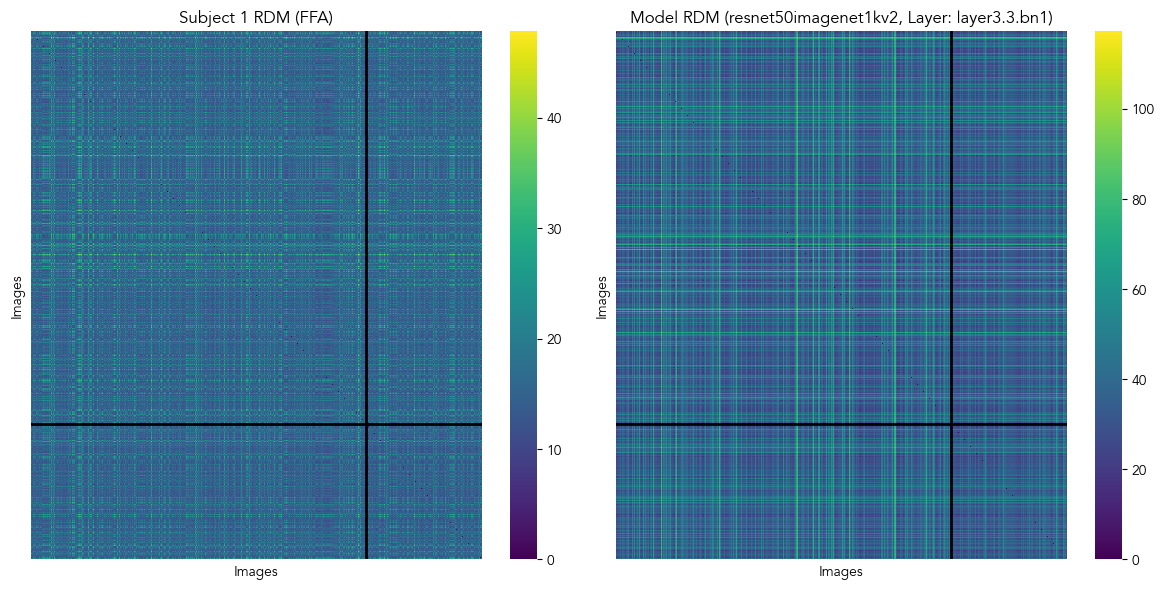

In [48]:
# sns plot heatmaps of the rdms side by side
plt.figure(figsize=(12, 6))

# Subject RDM
plt.subplot(1, 2, 1)
sns.heatmap(subject_rdm, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title(f'Subject {subject} RDM ({froi})')
plt.xlabel('Images')
plt.ylabel('Images')

# Add black lines to separate categories (assuming categories array indicates the categories in order)
separation_idx = np.where(categories == 'animal')[0][0].item() # Assume all person images come before animal images
plt.axhline(y=separation_idx, color='black', linewidth=2)
plt.axvline(x=separation_idx, color='black', linewidth=2)

# Model RDM
plt.subplot(1, 2, 2)
sns.heatmap(model_rdm, cmap='viridis', xticklabels=False, yticklabels=False)
plt.title(f'Model RDM ({model_name}, Layer: {layer})')
plt.xlabel('Images')
plt.ylabel('Images')

# Add the same separation lines to model RDM
plt.axhline(y=separation_idx, color='black', linewidth=2)
plt.axvline(x=separation_idx, color='black', linewidth=2)

plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/rdm_comparison_{froi}_subject{subject}_model_{model_name}_layer_{layer}.png', dpi=300)
plt.show()

# Explore: Person vs. non-person spread

In [7]:
# Variabes
subject = 1
froi = 'FFA'
tthreshold = 7

model_name = 'resnet50imagenet1kv2'
layer = ma.get_froi_models_layers(froi, froi)[model_name]
model = ma.get_model(model_name)

# shared1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

# Get subject data
subject_data, images_df = nsd.get_betas(
    NSD_DIR, subject, froi, tthreshold, voxels=True
)
# Add COCO labels to images_df
images_df = add_image_info_to_df(images_df)
subject_images_df = images_df.copy()
# # Filter out nsdIds that are in stim1000_nsdids
# subject_images_df = images_df[~images_df['nsdId'].isin(shared1000_nsdids)].reset_index(drop=True)
# subject_data = subject_data[~images_df['nsdId'].isin(shared1000_nsdids)]
subject_nsdids = subject_images_df['nsdId'].values
# Get stimuli
nsdcoco_stim = nsd.get_stimuli_dataset(
    NSD_DIR, transform=None, subset=None
).all_stimuli
stimuli = nsdcoco_stim[subject_nsdids]
stimuli = torch.tensor(stimuli)
# Get model data
model_data = model_utils.get_dataset_activations(
    MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, tthreshold, froi_localizer='grillspector',
    froi_localizer_dir=GRILLSPECTOR_LOCALIZER_DIR, device='cpu'
)
model_data = model_data[subject_nsdids]

# Expected shapes
# subject_data: (num_images, num_voxels)
# model_data: (num_images, num_features)
# stimuli: (num_images, height, width, channels)
print("Subject data shape:", subject_data.shape)
print("Model data shape:", model_data.shape)
print("Stimuli shape:", stimuli.shape)

n_samples = subject_data.shape[0]
print("Number of samples:", n_samples)

Subject data shape: torch.Size([10000, 156])
Model data shape: torch.Size([10000, 729])
Stimuli shape: torch.Size([10000, 425, 425, 3])
Number of samples: 10000


## Separation of unit/voxel-averaged responses of single label images for person vs. non-person images

In [ ]:
subject_images_df_singlelabel = subject_images_df[
    subject_images_df['labels'].apply(len) == 1
]
print("Number of images with single label:", len(subject_images_df_singlelabel))
# Get their ptids
singlelabel_ptids = subject_images_df_singlelabel['ptId'].values
# Subject data for single label images
subject_data_singlelabel = subject_data[singlelabel_ptids].mean(axis=-1)
# Model data for single label images
model_data_singlelabel = model_data[singlelabel_ptids].mean(axis=-1)
# Stimuli for single label images
stimuli_singlelabel = stimuli[singlelabel_ptids]

singlelabel_responses_df = []

for ptid_idx, ptid in enumerate(singlelabel_ptids):
    labels = subject_images_df_singlelabel.iloc[ptid_idx]['labels']
    caption = subject_images_df_singlelabel.iloc[ptid_idx]['captions']
    nsdId = subject_images_df_singlelabel.iloc[ptid_idx]['nsdId']
    cocoId = subject_images_df_singlelabel.iloc[ptid_idx]['cocoId']
    cocoSplit = subject_images_df_singlelabel.iloc[ptid_idx]['cocoSplit']
    subject_response = subject_data_singlelabel[ptid_idx].item()
    model_response = model_data_singlelabel[ptid_idx].item()
    singlelabel_responses_df.append({
        'ptId': ptid,
        'labels': labels[0],  # Single label
        'subject_response': subject_response,
        'model_response': model_response,
        'nsdId': nsdId,
        'cocoId': cocoId,
        'cocoSplit': cocoSplit,
        'caption': caption[0] if caption else '',  # First caption or empty string
    })
singlelabel_responses_df = pd.DataFrame(singlelabel_responses_df)

Number of images with single label: 2435


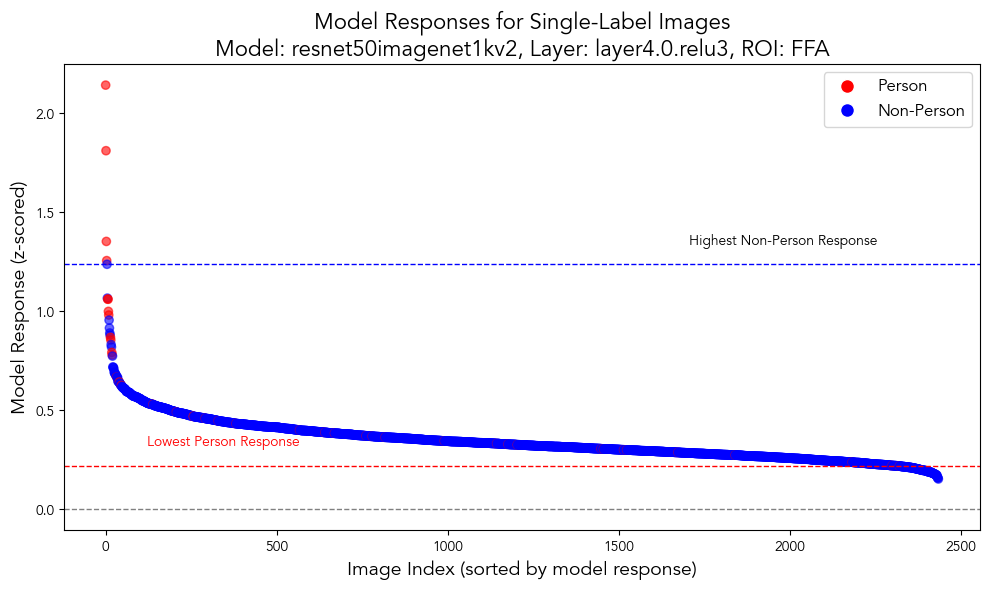

In [20]:
# Sort singlelabel_responses_df descending by 'model_response'
singlelabel_responses_df = singlelabel_responses_df.sort_values(by='model_response', ascending=False).reset_index(drop=True)
# Plot scatter plot of the model responses with index as x-axis
# Color the points by the labels (specifically person vs non-person)
plt.figure(figsize=(10, 6))
# Define colors for person vs non-person
colors = ['red' if 'person' in labels else 'blue' for labels in singlelabel_responses_df['labels']]
plt.scatter(range(len(singlelabel_responses_df)), singlelabel_responses_df['model_response'], c=colors, alpha=0.6)

# Make a horizontal line at lowest person response and at highest non-person response
lowest_person_response = singlelabel_responses_df[singlelabel_responses_df['labels'] == 'person']['model_response'].min()
plt.axhline(lowest_person_response, color='red', linestyle='--', linewidth=1, label='Lowest Person Response')
plt.text(len(singlelabel_responses_df)*0.05, lowest_person_response + 0.1, 'Lowest Person Response', color='red', fontsize=10)
highest_nonperson_response = singlelabel_responses_df[singlelabel_responses_df['labels'] != 'person']['model_response'].max()
plt.axhline(highest_nonperson_response, color='blue', linestyle='--', linewidth=1, label='Highest Non-Person Response')
plt.text(len(singlelabel_responses_df)*0.7, highest_nonperson_response + 0.1, 'Highest Non-Person Response', color='k', fontsize=10)

plt.xlabel('Image Index (sorted by model response)', fontsize=14)
plt.ylabel('Model Response (z-scored)', fontsize=14)
plt.title(f'Model Responses for Single-Label Images\nModel: {model_name}, Layer: {layer}, ROI: {froi}', fontsize=16)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
# Create custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Person', markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Non-Person', markerfacecolor='blue', markersize=10)
]
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()
# plt.savefig(f'{PLOTS_DIR}/model_responses_scatter_{model_name}_{layer}_{froi}_singlelabel.png', dpi=300)
plt.show()
plt.close()

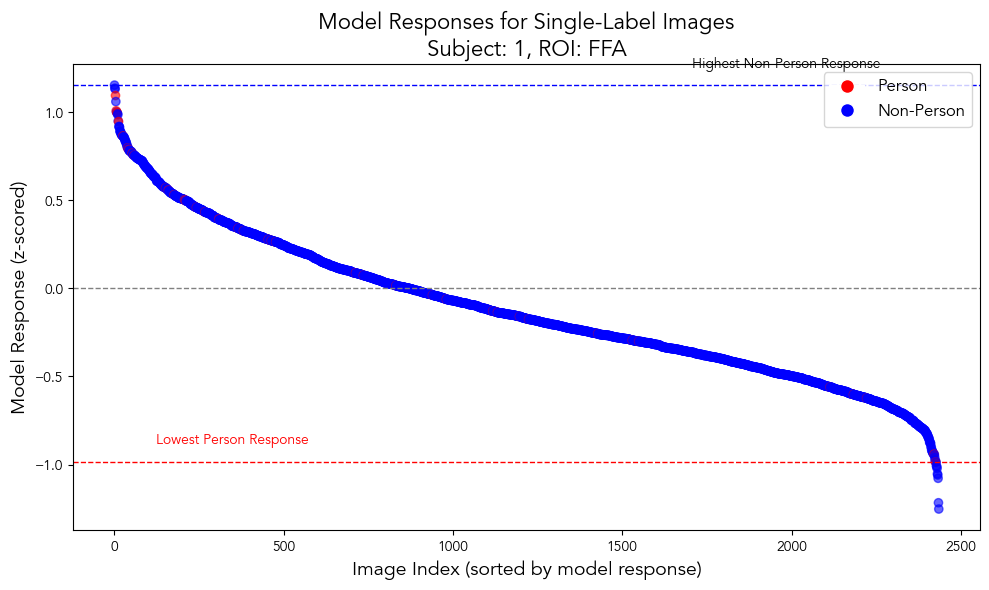

In [21]:
# Sort singlelabel_responses_df descending by 'subject_response'
singlelabel_responses_df = singlelabel_responses_df.sort_values(by='subject_response', ascending=False).reset_index(drop=True)
# Plot scatter plot of the model responses with index as x-axis
# Color the points by the labels (specifically person vs non-person)
plt.figure(figsize=(10, 6))
# Define colors for person vs non-person
colors = ['red' if 'person' in labels else 'blue' for labels in singlelabel_responses_df['labels']]
plt.scatter(range(len(singlelabel_responses_df)), singlelabel_responses_df['subject_response'], c=colors, alpha=0.6)

# Make a horizontal line at lowest person response and at highest non-person response
lowest_person_response = singlelabel_responses_df[singlelabel_responses_df['labels'] == 'person']['subject_response'].min()
plt.axhline(lowest_person_response, color='red', linestyle='--', linewidth=1, label='Lowest Person Response')
plt.text(len(singlelabel_responses_df)*0.05, lowest_person_response + 0.1, 'Lowest Person Response', color='red', fontsize=10)
highest_nonperson_response = singlelabel_responses_df[singlelabel_responses_df['labels'] != 'person']['subject_response'].max()
plt.axhline(highest_nonperson_response, color='blue', linestyle='--', linewidth=1, label='Highest Non-Person Response')
plt.text(len(singlelabel_responses_df)*0.7, highest_nonperson_response + 0.1, 'Highest Non-Person Response', color='k', fontsize=10)

plt.xlabel('Image Index (sorted by model response)', fontsize=14)
plt.ylabel('Model Response (z-scored)', fontsize=14)
plt.title(f'Model Responses for Single-Label Images\nSubject: {subject}, ROI: {froi}', fontsize=16)
plt.axhline(0, color='gray', linestyle='--', linewidth=1)
# Create custom legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Person', markerfacecolor='red', markersize=10),
    Line2D([0], [0], marker='o', color='w', label='Non-Person', markerfacecolor='blue', markersize=10)
]
plt.legend(handles=legend_elements, loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()
# plt.savefig(f'{PLOTS_DIR}/subject_responses_scatter_{model_name}_{layer}_{froi}_singlelabel.png', dpi=300)
plt.show()
plt.close()

In [22]:
images_df_withperson = subject_images_df[
    subject_images_df['labels'].apply(lambda labels: 'person' in labels)
]
withperson_ptids = images_df_withperson['ptId'].values
images_df_noperson = subject_images_df[
    subject_images_df['labels'].apply(lambda labels: 'person' not in labels)
]
noperson_ptids = images_df_noperson['ptId'].values

withperson_pearsonr = rcutils.pearsonr(
    subject_data[withperson_ptids].mean(axis=-1),
    model_data[withperson_ptids].mean(axis=-1)
)
withperson_rdmr = rcutils.rdmr(
    subject_data[withperson_ptids],
    model_data[withperson_ptids]
)
noperson_pearsonr = rcutils.pearsonr(
    subject_data[noperson_ptids].mean(axis=-1),
    model_data[noperson_ptids].mean(axis=-1)
)
noperson_rdmr = rcutils.rdmr(
    subject_data[noperson_ptids],
    model_data[noperson_ptids]
)
print(f"With person - Pearson r: {withperson_pearsonr:.4f}, RDMR: {withperson_rdmr:.4f}")
print(f"Without person - Pearson r: {noperson_pearsonr:.4f}, RDMR: {noperson_rdmr:.4f}")

With person - Pearson r: 0.6702, RDMR: 0.1700
Without person - Pearson r: 0.4873, RDMR: 0.2456


## Unit/Voxel-averaged responses of single label images across all categories

In [ ]:
singlelabel_responses_df_zscored = singlelabel_responses_df.copy()

# z-score the responses
singlelabel_responses_df_zscored['subject_response'] = (
    singlelabel_responses_df_zscored['subject_response'] - singlelabel_responses_df_zscored['subject_response'].mean()
) / singlelabel_responses_df_zscored['subject_response'].std()
singlelabel_responses_df_zscored['model_response'] = (
    singlelabel_responses_df_zscored['model_response'] - singlelabel_responses_df_zscored['model_response'].mean()
) / singlelabel_responses_df_zscored['model_response'].std()

# Group by label and compute mean responses
grouped_responses = singlelabel_responses_df_zscored.groupby("labels").agg(
    subject_response_mean=("subject_response", "mean"),
    subject_response_sem=("subject_response", lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    model_response_mean=("model_response", "mean"),
    model_response_sem=("model_response", lambda x: x.std(ddof=1) / np.sqrt(len(x))),
    image_count=("ptId", "count")
).reset_index()
grouped_responses = grouped_responses.fillna(0)

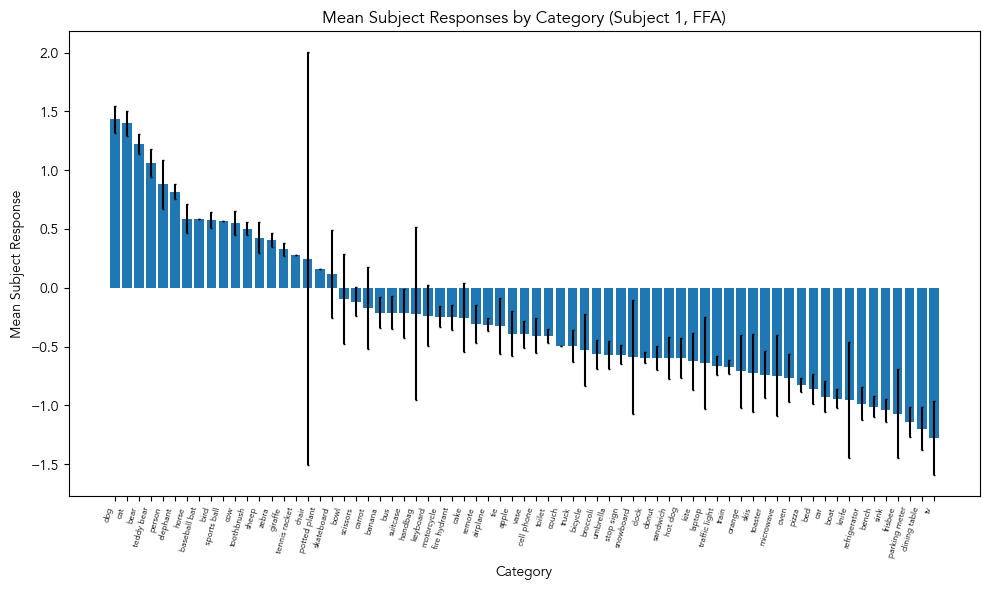

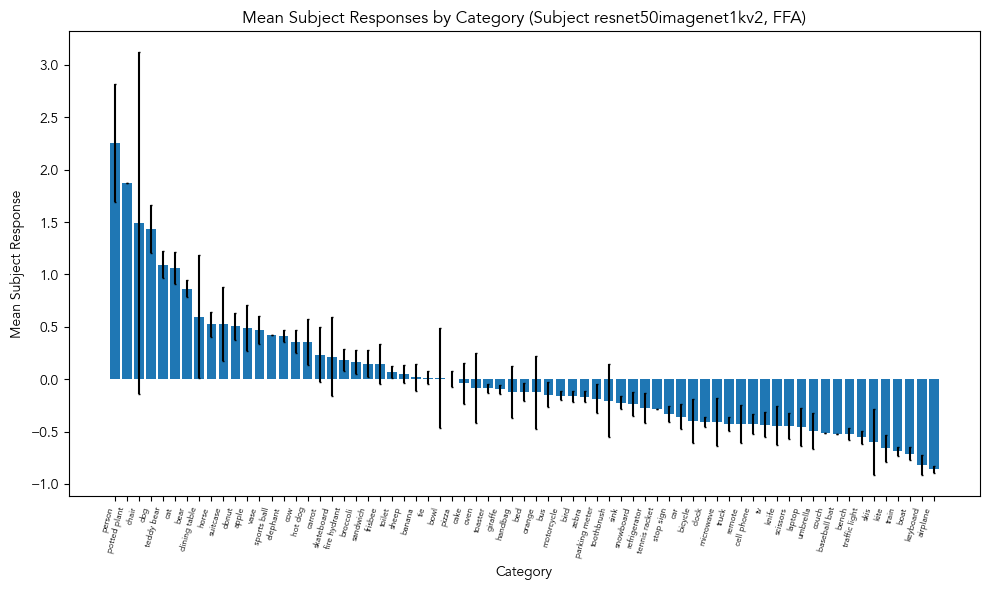

In [51]:
grouped_responses_sbjsorted = grouped_responses.sort_values(by="subject_response_mean", ascending=False)
# Plot a compact bar plot with error bars for subject responses
plt.figure(figsize=(10, 6))
plt.bar(
    grouped_responses_sbjsorted["labels"],
    grouped_responses_sbjsorted["subject_response_mean"],
    yerr=grouped_responses_sbjsorted["subject_response_sem"],
    capsize=1
)
plt.xticks(rotation=75, ha='right', fontsize=6)
plt.xlabel("Category")
plt.ylabel("Mean Subject Response")
plt.title(f"Mean Subject Responses by Category (Subject {subject}, {froi})")
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_{subject}_{froi}_mean_responses_by_category.png', dpi=300)
plt.show()
plt.close()

grouped_responses_sbjsorted = grouped_responses.sort_values(by="model_response_mean", ascending=False)
# Plot a compact bar plot with error bars for model responses
plt.figure(figsize=(10, 6))
plt.bar(
    grouped_responses_sbjsorted["labels"],
    grouped_responses_sbjsorted["model_response_mean"],
    yerr=grouped_responses_sbjsorted["model_response_sem"],
    capsize=1
)
plt.xticks(rotation=75, ha='right', fontsize=6)
plt.xlabel("Category")
plt.ylabel("Mean Subject Response")
plt.title(f"Mean Subject Responses by Category (Subject {model.name}, {froi})")
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_{model}_{froi}_mean_responses_by_category.png', dpi=300)
plt.show()
plt.close()

## Category-spread of THINGS dataset unit-averaged model responses

In [36]:
from compcats.datasets.image import things
things_dataset = things.get_stimuli_dataset(
    paths.THINGS_DIR, transform=model.transforms
)

In [37]:
things_activations = model.generate_dataset_activations(
    layer, things_dataset, save_dir=MODELS_DIR, batch_size=1024, device='cuda'
)

  0%|          | 0/26 [00:00<?, ?it/s]

100%|██████████| 26/26 [07:29<00:00, 17.27s/it]


In [ ]:
model_froi_mask = localizer.get_froi_mask(
    GRILLSPECTOR_LOCALIZER_DIR, 'grillspector', MODELS_DIR, model, layer, froi=froi,
    tthreshold=tthreshold
)
things_activations_froi = things_activations[:, model_froi_mask]

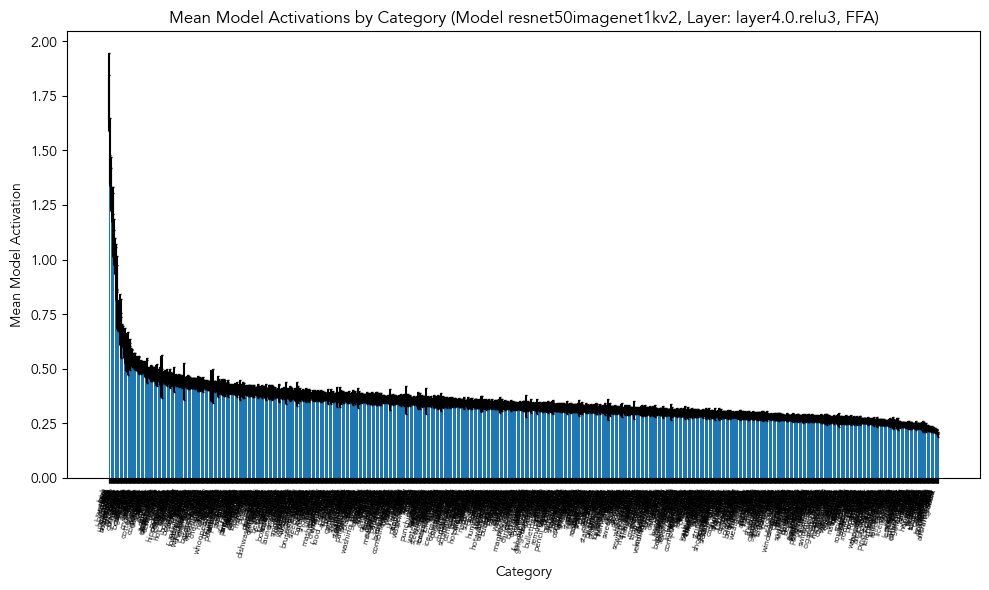

In [ ]:
model_things_mean_act_df = []
for i in range(len(things_dataset.image_paths)):
    img_class = things_dataset.image_paths[i].split('/')[1]
    model_things_mean_act_df.append({
        'image_idx': i,
        'image_class': img_class,
        'mean_activation': things_activations_froi[i].mean().item()
    })
model_things_mean_act_df = pd.DataFrame(model_things_mean_act_df)
model_things_mean_act_df_grouped = model_things_mean_act_df.groupby('image_class').agg(
    mean_activation=('mean_activation', 'mean'),
    sem_activation=('mean_activation', lambda x: x.std(ddof=1) / np.sqrt(len(x))),
).reset_index()
model_things_mean_act_df_grouped = model_things_mean_act_df_grouped.sort_values(by='mean_activation', ascending=False)


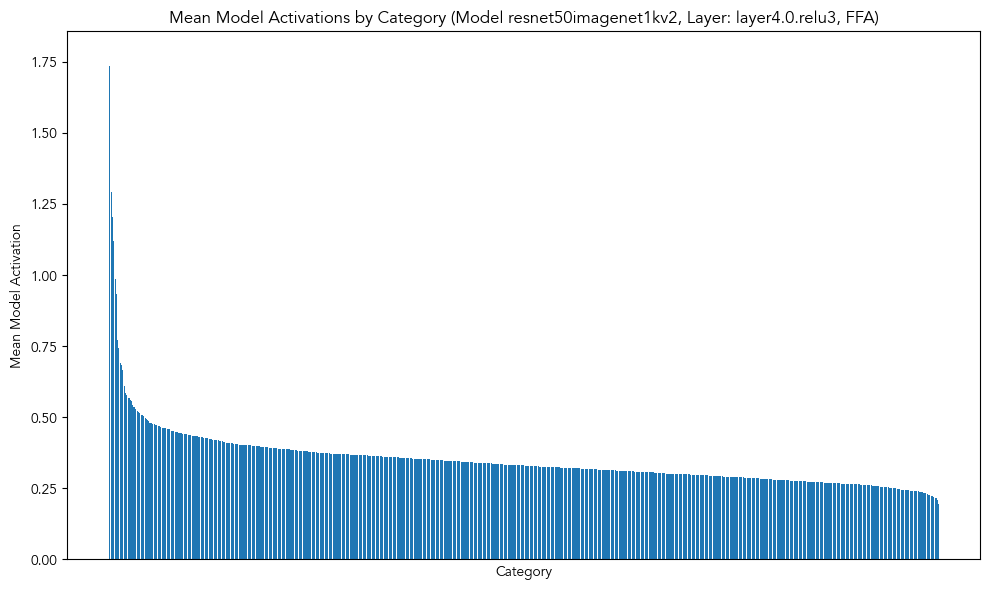

In [62]:
# Plot a compact bar plot with error bars for model responses
plt.figure(figsize=(10, 6))
plt.bar(
    model_things_mean_act_df_grouped["image_class"],
    model_things_mean_act_df_grouped["mean_activation"],
    # yerr=model_things_mean_act_df_grouped["sem_activation"],
    capsize=0
)
plt.xticks([], [])
# plt.xticks(rotation=75, ha='right', fontsize=6)
plt.xlabel("Category")
plt.ylabel("Mean Model Activation")
plt.title(f"Mean Model Activations by Category (Model {model_name}, Layer: {layer}, {froi})")
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/model_{model_name}_{layer}_{froi}_mean_activations_by_category_things.png', dpi=300)
plt.show()
plt.close()

In [67]:
model_things_mean_act_df_sorted = model_things_mean_act_df.sort_values(by='mean_activation', ascending=False)
# Make a histogram of labels in the top 100 mean activations
model_things_mean_act_df_sorted.iloc[:100]['image_class'].value_counts()

image_class
baby           13
girl           12
boy            10
blindfold       9
woman           8
wig             8
mullet          6
man             5
doll            4
hairnet         4
headband        3
face            3
eye_patch       2
hair            2
braid           2
headlamp        2
headscarf       1
bandanna        1
ear             1
bow1            1
barrette        1
hearing_aid     1
inhaler         1
Name: count, dtype: int64